# Gathering Data

SDSS DR17: 5,000 galaxies. Inputs: full observed spectra. Targets: `z`, `cModelMag_g`, `cModelMag_r`, `cModelMag_i`.

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import time

import numpy as np
import pandas as pd
import requests
from astropy.io import fits
from astroquery.sdss import SDSS
from IPython.display import display

N_GALAXIES = 5000
DATA_RELEASE = 17
SEED = 42
TARGET_COLUMNS = ["z", "cModelMag_g", "cModelMag_r", "cModelMag_i"]
DATA_DIR = Path("data") / "dr17_5000"
SPECTRA_DIR = DATA_DIR / "spectra"
SPECTRA_DIR.mkdir(parents=True, exist_ok=True)
CATALOG_PATH = DATA_DIR / "galaxies.csv"


def spectrum_path(row):
    return SPECTRA_DIR / f"spec-{int(row['plate']):04d}-{int(row['mjd'])}-{int(row['fiberID']):04d}.fits"

## Select galaxies

Join primary spectroscopic observations to their position-matched photometry. Require no redshift warnings, positive redshift, clean photometry, and g/r/i magnitudes between 0 and 40 with positive measurement errors. These cuts define our sample. A deterministic checksum ordering spreads selection across the eligible catalog instead of taking the first observation IDs; it is not a scientifically representative sampling design. The saved catalog fixes the sample on subsequent runs.

[Primary spectra](https://www.sdss4.org/dr17/spectro/catalogs/) ? [Magnitude definitions](https://www.sdss4.org/dr17/algorithms/magnitudes/)

In [2]:
query = f"""
SELECT TOP {N_GALAXIES}
    s.specObjID, s.bestObjID AS objID,
    s.plate, s.mjd, s.fiberID, s.run2d,
    s.ra, s.dec, s.z, s.zErr, s.zWarning,
    p.cModelMag_g, p.cModelMag_r, p.cModelMag_i,
    p.cModelMagErr_g, p.cModelMagErr_r, p.cModelMagErr_i
FROM SpecObj AS s
JOIN PhotoObjAll AS p ON p.objID = s.bestObjID
WHERE s.class = 'GALAXY'
    AND s.zWarning = 0 AND s.z > 0
    AND p.clean = 1
    AND p.cModelMag_g BETWEEN 0 AND 40
    AND p.cModelMag_r BETWEEN 0 AND 40
    AND p.cModelMag_i BETWEEN 0 AND 40
    AND p.cModelMagErr_g > 0
    AND p.cModelMagErr_r > 0
    AND p.cModelMagErr_i > 0
ORDER BY CHECKSUM(s.specObjID, {SEED}), s.specObjID
"""

if CATALOG_PATH.exists():
    galaxies = pd.read_csv(CATALOG_PATH, dtype={"specObjID": "string", "objID": "string", "run2d": "string"})
else:
    result = SDSS.query_sql(query, data_release=DATA_RELEASE, timeout=300)
    if result is None:
        raise RuntimeError("SkyServer returned no rows.")
    galaxies = result.to_pandas()
    for column in ["specObjID", "objID", "run2d"]:
        galaxies[column] = galaxies[column].astype("string")

assert len(galaxies) == N_GALAXIES, f"Expected {N_GALAXIES} galaxies; got {len(galaxies)}"
assert galaxies["specObjID"].is_unique, "Repeated spectrum IDs"
assert galaxies["objID"].is_unique, "Repeated photometric objects"
assert np.isfinite(galaxies[TARGET_COLUMNS].to_numpy(dtype=float)).all()
galaxies.to_csv(CATALOG_PATH, index=False)
(DATA_DIR / "selection.sql").write_text(query, encoding="utf-8")

y = galaxies.set_index("specObjID")[TARGET_COLUMNS].copy()
y.to_csv(DATA_DIR / "targets.csv")
print(f"Selected {len(galaxies):,} unique galaxies; targets: {TARGET_COLUMNS}")
display(galaxies.head())
display(y.describe())

Selected 5,000 unique galaxies; targets: ['z', 'cModelMag_g', 'cModelMag_r', 'cModelMag_i']


,specObjID,objID,plate,mjd,fiberID,run2d,ra,dec,z,zErr,zWarning,cModelMag_g,cModelMag_r,cModelMag_i,cModelMagErr_g,cModelMagErr_r,cModelMagErr_i
0,1792589657142224896,1237661383844102419,1592,52990,571,26,140.33829,33.691305,0.042719,0.000012,0,16.83346,16.33622,15.99491,0.005736,0.005118,0.005429
1,5842516270105516032,1237659324417901186,5189,56074,806,v5_13_2,244.24967,40.177549,0.447190,0.000102,0,20.59454,19.31710,18.69562,0.081923,0.024749,0.020313
2,1966957084448679936,1237664131016949841,1747,53075,36,26,158.37135,13.032713,0.114140,0.000012,0,16.97006,16.29156,15.90843,0.004425,0.003838,0.003927
3,8540035301548251136,1237680298883155015,7585,57190,307,v5_13_2,338.84017,20.923247,0.709567,0.000200,0,22.14760,21.73308,20.62036,0.312303,0.269704,0.087038
4,1879216337436305408,1237657630608195703,1669,53433,325,26,204.64971,51.800109,0.091199,0.000021,0,17.97273,17.14472,16.78324,0.006907,0.005220,0.005511


,z,cModelMag_g,cModelMag_r,cModelMag_i
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.405396,20.682904,19.438362,18.706451
std,0.236763,2.020099,1.771925,1.556176
min,0.001680,13.785370,13.024880,12.669280
25%,0.171541,18.792862,17.747393,17.332127
50%,0.448757,21.262950,19.959925,19.150940
75%,0.571696,22.227195,20.802290,19.751960
max,1.258816,29.617270,23.582080,24.068590


## Download full spectra

Downloads resume from valid local FITS files, with four workers and three attempts per file. Failures are recorded and retried when rerun. Expect several GB of downloads. Each spectrum retains its native wavelength grid, flux, inverse variance, and quality masks. Alignment onto a common wavelength grid will be a separate preprocessing step. Catalog measurements are targets and metadata, not model inputs.

In [3]:
def validate_spectrum(path, row):
    with fits.open(path, memmap=False) as hdul:
        header = hdul[0].header
        for key, column in [("PLATEID", "plate"), ("FIBERID", "fiberID")]:
            if int(header[key]) != int(row[column]):
                raise ValueError(f"Spectrum identity mismatch in primary header: {key}")
        # The object metadata table identifies the coadded spectrum. Some files
        # (e.g. plate 389 / MJD 51795) have a different primary-header MJD.
        metadata = hdul[2].data
        if metadata is None or len(metadata) != 1:
            raise ValueError("Missing or ambiguous spectrum identity metadata")
        for key, column in [("SPECOBJID", "specObjID"), ("PLATE", "plate"),
                            ("MJD", "mjd"), ("FIBERID", "fiberID")]:
            if int(metadata[key][0]) != int(row[column]):
                raise ValueError(f"Spectrum identity mismatch in object metadata: {key}")
        data = hdul[1].data
        required = {"flux", "loglam", "ivar", "and_mask", "or_mask"}
        if not required.issubset(data.names):
            raise ValueError("Missing spectrum columns")
        valid = np.isfinite(data["flux"]) & np.isfinite(data["loglam"]) & (data["ivar"] > 0)
        if not valid.any():
            raise ValueError("No usable spectral pixels")
        return len(data)


def download_spectrum(row):
    path = spectrum_path(row)
    temporary = path.with_suffix(".fits.part")
    error = ""
    for attempt in range(3):
        try:
            if path.exists():
                try:
                    pixels = validate_spectrum(path, row)
                    return {"specObjID": str(row["specObjID"]), "path": path.as_posix(), "pixels": pixels, "status": "ok", "error": ""}
                except (OSError, ValueError, KeyError):
                    pass  # Replace an invalid local file with a fresh download.
            run2d = str(row["run2d"])
            branch = "spectra" if run2d in ("26", "103", "104") else "spectra/full"
            url = (f"https://dr17.sdss.org/sas/dr17/sdss/spectro/redux/{run2d}/"
                   f"{branch}/{int(row['plate']):04d}/{path.name}")
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                with temporary.open("wb") as output:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        output.write(chunk)
            pixels = validate_spectrum(temporary, row)
            temporary.replace(path)
            return {"specObjID": str(row["specObjID"]), "path": path.as_posix(), "pixels": pixels, "status": "ok", "error": ""}
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            temporary.unlink(missing_ok=True)
            if attempt < 2:
                time.sleep(2 ** attempt)
    return {"specObjID": str(row["specObjID"]), "path": path.as_posix(), "pixels": None, "status": "failed", "error": error}


def download_spectra(catalog):
    results = []
    with ThreadPoolExecutor(max_workers=4) as executor:
        futures = [executor.submit(download_spectrum, row) for row in catalog.to_dict("records")]
        for future in as_completed(futures):
            results.append(future.result())
            if len(results) % 100 == 0 or len(results) == len(catalog):
                print(f"Checked {len(results):,}/{len(catalog):,} spectra", flush=True)
    manifest = pd.DataFrame(results)
    return catalog[["specObjID"]].merge(manifest, on="specObjID", validate="one_to_one")

In [4]:
manifest = download_spectra(galaxies)
manifest.to_csv(DATA_DIR / "spectra_manifest.csv", index=False)
failed = manifest.loc[manifest["status"] != "ok"]
failed.to_csv(DATA_DIR / "download_failures.csv", index=False)
print(f"Ready: {(manifest['status'] == 'ok').sum():,}/{N_GALAXIES:,} spectra")
if not failed.empty:
    display(failed)
    raise RuntimeError("Some spectra failed. Rerun this cell to retry; valid files will be reused.")

dataset = galaxies.merge(manifest[["specObjID", "path", "pixels"]], on="specObjID", validate="one_to_one")
dataset.to_csv(DATA_DIR / "dataset.csv", index=False)
display(dataset[["specObjID", "path"] + TARGET_COLUMNS].head())

Checked 100/5,000 spectra


Checked 200/5,000 spectra


Checked 300/5,000 spectra


Checked 400/5,000 spectra


Checked 500/5,000 spectra


Checked 600/5,000 spectra


... (42 outputs left out)

Checked 4,900/5,000 spectra


Checked 5,000/5,000 spectra


Ready: 5,000/5,000 spectra


,specObjID,path,z,cModelMag_g,cModelMag_r,cModelMag_i
0,1792589657142224896,data/dr17_5000/spectra/spec-1592-52990-0571.fits,0.042719,16.83346,16.33622,15.99491
1,5842516270105516032,data/dr17_5000/spectra/spec-5189-56074-0806.fits,0.447190,20.59454,19.31710,18.69562
2,1966957084448679936,data/dr17_5000/spectra/spec-1747-53075-0036.fits,0.114140,16.97006,16.29156,15.90843
3,8540035301548251136,data/dr17_5000/spectra/spec-7585-57190-0307.fits,0.709567,22.14760,21.73308,20.62036
4,1879216337436305408,data/dr17_5000/spectra/spec-1669-53433-0325.fits,0.091199,17.97273,17.14472,16.78324


## Read spectra

In [3]:
spectrum_previews = []
for row in galaxies.head(2).to_dict("records"):
    with fits.open(spectrum_path(row), memmap=False) as hdul:
        spectrum = hdul[1].data
        inverse_variance = spectrum["ivar"].astype(float)
        usable_uncertainty = np.isfinite(inverse_variance) & (inverse_variance > 0)
        variance = np.full(len(spectrum), np.nan)
        np.divide(1.0, inverse_variance, out=variance, where=usable_uncertainty)
        uncertainty = np.sqrt(variance)
        spectrum_previews.append(pd.DataFrame({
            "specObjID": str(row["specObjID"]),
            "pixel": np.arange(1, len(spectrum) + 1),
            "loglam": spectrum["loglam"].astype(float),
            "wavelength_angstrom": 10.0 ** spectrum["loglam"].astype(float),
            "flux": spectrum["flux"].astype(float),
            "inverse_variance": inverse_variance,
            "flux_variance": variance,
            "flux_uncertainty": uncertainty,
            "and_mask": spectrum["and_mask"].astype(int),
            "or_mask": spectrum["or_mask"].astype(int),
        }))

spectra_table = pd.concat(spectrum_previews, ignore_index=True)
# Keep every pixel in memory; abbreviate only the displayed tables.
# Uncertainty is NaN where inverse variance is zero or invalid.
with pd.option_context("display.max_rows", 8, "display.min_rows", 8,
                       "display.max_columns", None):
    for preview in spectrum_previews:
        display(preview.set_index(["specObjID", "pixel"]))

loglam  wavelength_angstrom       flux  \
specObjID           pixel                                           
1792589657142224896 1      3.5820          3819.442859  11.625899   
                    2      3.5821          3820.321517   8.731327   
                    3      3.5822          3821.202475   4.455827   
                    4      3.5823          3822.081537   8.515337   
...                           ...                  ...        ...   
                    3825   3.9644          9212.978402   8.159941   
                    3826   3.9645          9215.097835   6.721214   
                    3827   3.9646          9217.222816   8.530977   
                    3828   3.9647          9219.343226  12.865065   

                           inverse_variance  flux_variance  flux_uncertainty  \
specObjID           pixel                                                      
1792589657142224896 1              0.236193       4.233832          2.057628   
                    2              0.253389       3.946505          1.986581   
                    3              0.270474       3.697220          1.922816   
                    4              0.267146       3.743268          1.934753   
...                                     ...            ...               ...   
                    3825           0.756741       1.321456          1.149546   
                    3826           0.693161       1.442667          1.201111   
                    3827           0.614556       1.627191          1.275614   
                    3828           0.543218       1.840880          1.356791   

                           and_mask  or_mask  
specObjID           pixel                     
1792589657142224896 1             0        0  
                    2             0        0  
                    3             0        0  
                    4             0        0  
...                             ...      ...  
                    3825          0        0  
                    3826          0        0  
                    3827          0        0  
                    3828          0        0  

[3828 rows x 8 columns]

loglam  wavelength_angstrom       flux  \
specObjID           pixel                                           
5842516270105516032 1      3.5546          3585.915078   1.866559   
                    2      3.5547          3586.740013  -1.194223   
                    3      3.5548          3587.567108  -6.708762   
                    4      3.5549          3588.392423  -7.181222   
...                           ...                  ...        ...   
                    4619   4.0164         10384.841212   3.686647   
                    4620   4.0165         10387.235933  14.298793   
                    4621   4.0166         10389.631207  19.611069   
                    4622   4.0167         10392.015623   5.706114   

                           inverse_variance  flux_variance  flux_uncertainty  \
specObjID           pixel                                                      
5842516270105516032 1              0.047831      20.906882          4.572404   
                    2              0.063915      15.645887          3.955488   
                    3              0.074416      13.437996          3.665787   
                    4              0.076003      13.157442          3.627319   
...                                     ...            ...               ...   
                    4619           0.007444     134.340734         11.590545   
                    4620           0.006479     154.341130         12.423411   
                    4621           0.023951      41.751865          6.461568   
                    4622           0.104807       9.541331          3.088905   

                           and_mask    or_mask  
specObjID           pixel                       
5842516270105516032 1             0          0  
                    2             0          0  
                    3             0          0  
                    4             0          0  
...                             ...        ...  
                    4619          0  167772160  
                    4620          0  167772160  
                    4621          0  167772160  
                    4622          0          0  

[4622 rows x 8 columns]

## Understanding the data: 10 galaxies

Compare the targets and native wavelength grids before interpolation. Wavelengths are in angstroms. Pixel numbers are positions within each file; the same pixel number does not necessarily represent the same wavelength.

## Shared wavelength range

Use the largest starting wavelength and the smallest ending wavelength across the available catalog spectra. Until all 5,000 files are downloaded, this range is provisional. This checks wavelength coverage, not pixel quality; masks and invalid flux measurements will be handled separately.

In [3]:
LOG_STEP = 0.0001
GRID_TOLERANCE_PIXELS = 0.005  # Allows float32 rounding of stored loglam values.
coverage_rows = []
missing_spectra = []
unreadable_spectra = []

for row in galaxies.to_dict("records"):
    path = spectrum_path(row)
    if not path.exists():
        missing_spectra.append(str(row["specObjID"]))
        continue
    try:
        with fits.open(path, memmap=False) as hdul:
            loglam = hdul[1].data["loglam"].astype(float)
        if len(loglam) < 2 or not np.isfinite(loglam).all() or not (np.diff(loglam) > 0).all():
            raise ValueError("Invalid wavelength grid")
        # Integer positions avoid tiny differences due to FITS float32 storage.
        grid_positions = np.rint(loglam / LOG_STEP).astype(np.int64)
        rounding_error = np.max(np.abs(loglam / LOG_STEP - grid_positions))
        on_shared_grid = bool(
            rounding_error <= GRID_TOLERANCE_PIXELS
            and (np.diff(grid_positions) == 1).all()
        )
        coverage_rows.append({
            "specObjID": str(row["specObjID"]),
            "n_pixels": len(loglam),
            "start_loglam": loglam[0],
            "end_loglam": loglam[-1],
            "start_wavelength_A": 10.0 ** loglam[0],
            "end_wavelength_A": 10.0 ** loglam[-1],
            "start_grid_position": grid_positions[0],
            "end_grid_position": grid_positions[-1],
            "on_shared_grid": on_shared_grid,
        })
    except (OSError, ValueError, KeyError, IndexError) as exc:
        unreadable_spectra.append({"specObjID": str(row["specObjID"]), "error": str(exc)})

spectrum_bounds = pd.DataFrame(coverage_rows)
if spectrum_bounds.empty:
    raise RuntimeError("No readable downloaded spectra are available.")

all_spectra_available = len(spectrum_bounds) == N_GALAXIES
print(f"Checked {len(spectrum_bounds):,}/{N_GALAXIES:,} spectra; "
      f"missing: {len(missing_spectra):,}; unreadable: {len(unreadable_spectra):,}")
if not all_spectra_available:
    print("PROVISIONAL: rerun after the full download; additional spectra may narrow the range.")
if unreadable_spectra:
    display(pd.DataFrame(unreadable_spectra))

# Intersection of coverage, rather than the overall minimum and maximum.
shared_start_loglam = spectrum_bounds["start_loglam"].max()
shared_end_loglam = spectrum_bounds["end_loglam"].min()
if shared_start_loglam >= shared_end_loglam:
    raise RuntimeError("The spectra have no common wavelength interval.")

coverage_summary = pd.DataFrame({
    "boundary": ["Largest starting wavelength", "Smallest ending wavelength"],
    "loglam": [shared_start_loglam, shared_end_loglam],
    "wavelength_angstrom": [10.0 ** shared_start_loglam, 10.0 ** shared_end_loglam],
})
display(coverage_summary)

# Define common pixel centres only if every checked spectrum uses this grid.
common_loglam = None
common_wavelength_angstrom = None
if spectrum_bounds["on_shared_grid"].all():
    first_position = int(spectrum_bounds["start_grid_position"].max())
    last_position = int(spectrum_bounds["end_grid_position"].min())
    common_grid_positions = np.arange(first_position, last_position + 1)
    common_loglam = common_grid_positions * LOG_STEP
    common_wavelength_angstrom = 10.0 ** common_loglam
    print(f"All checked spectra align with the shared logarithmic grid within rounding tolerance.")
    print(f"Shared grid: {len(common_loglam):,} wavelength centres, "
          f"{common_wavelength_angstrom[0]:.3f} to {common_wavelength_angstrom[-1]:.3f} Angstrom")
else:
    print("Some grids do not align. Check them before creating a common flux table.")
    display(spectrum_bounds.loc[~spectrum_bounds["on_shared_grid"]])

Checked 980/5,000 spectra; missing: 4,020; unreadable: 0
PROVISIONAL: rerun after the full download; additional spectra may narrow the range.


,boundary,loglam,wavelength_angstrom
0,Largest starting wavelength,3.5849,3845.031502
1,Smallest ending wavelength,3.9605,9130.614393


All checked spectra align with the shared logarithmic grid within rounding tolerance.
Shared grid: 3,757 wavelength centres, 3845.032 to 9130.614 Angstrom


## Intersection versus average spectrum coverage

Compare the wavelength interval shared by every checked galaxy with the average individual interval and the full combined range (union). Widths are in angstroms; pixel counts describe sampling rather than information content. These are provisional results until all 5,000 spectra are available. Rerun the shared-range cell before this comparison.

In [4]:
individual_widths = spectrum_bounds["end_wavelength_A"] - spectrum_bounds["start_wavelength_A"]
intersection_start = spectrum_bounds["start_wavelength_A"].max()
intersection_end = spectrum_bounds["end_wavelength_A"].min()
intersection_width = intersection_end - intersection_start
union_start = spectrum_bounds["start_wavelength_A"].min()
union_end = spectrum_bounds["end_wavelength_A"].max()

aligned_grids = bool(spectrum_bounds["on_shared_grid"].all())
intersection_pixels = (int(spectrum_bounds["end_grid_position"].min())
                       - int(spectrum_bounds["start_grid_position"].max()) + 1) if aligned_grids else np.nan
union_pixels = (int(spectrum_bounds["end_grid_position"].max())
               - int(spectrum_bounds["start_grid_position"].min()) + 1) if aligned_grids else np.nan

interval_comparison = pd.DataFrame([
    {"interval": "Intersection (shared by all checked)",
     "start_A": intersection_start, "end_A": intersection_end,
     "width_A": intersection_width, "n_pixels": intersection_pixels},
    {"interval": "Average individual spectrum",
     "start_A": spectrum_bounds["start_wavelength_A"].mean(),
     "end_A": spectrum_bounds["end_wavelength_A"].mean(),
     "width_A": individual_widths.mean(), "n_pixels": spectrum_bounds["n_pixels"].mean()},
    {"interval": "Union (full combined range)",
     "start_A": union_start, "end_A": union_end,
     "width_A": union_end - union_start, "n_pixels": union_pixels},
]).set_index("interval")

print(f"Comparison based on {len(spectrum_bounds):,}/{N_GALAXIES:,} spectra.")
if len(spectrum_bounds) < N_GALAXIES:
    print("PROVISIONAL: the intersection may narrow as more spectra become available.")
with pd.option_context("display.max_columns", None):
    display(interval_comparison.round(3))

if aligned_grids:
    # Every spectrum contributes the same number of pixels after intersection cropping.
    pixel_percent_retained = 100.0 * intersection_pixels / spectrum_bounds["n_pixels"]
    print(f"Mean fraction of each spectrum's pixels retained: {pixel_percent_retained.mean():.2f}%")
    print(f"Mean fraction cropped: {100.0 - pixel_percent_retained.mean():.2f}%")
print(f"Mean fraction of each spectrum's wavelength span retained: "
      f"{(100.0 * intersection_width / individual_widths).mean():.2f}%")
print("Coverage does not account for unusable pixels or quality masks.")

Comparison based on 980/5,000 spectra.
PROVISIONAL: the intersection may narrow as more spectra become available.


,start_A,end_A,width_A,n_pixels
interval,,,,
Intersection (shared by all checked),3845.032,9130.614,5285.583,3757.000
Average individual spectrum,3650.102,10007.162,6357.059,4376.524
Union (full combined range),3536.714,10401.593,6864.879,4686.000


Mean fraction of each spectrum's pixels retained: 86.47%
Mean fraction cropped: 13.53%
Mean fraction of each spectrum's wavelength span retained: 84.07%
Coverage does not account for unusable pixels or quality masks.


# Data preparation

## Identify unusable flux measurements

Flag non-finite flux, non-finite inverse variance, or inverse variance less than or equal to zero. Keep a Boolean mask for each galaxy and summarize the counts without changing the flux values. This check uses the original spectra; quality-bitmask decisions are separate.

In [3]:
unusable_flux_masks = {}
flux_quality_rows = []
missing_flux_files = []
unreadable_flux_files = []

for row in galaxies.to_dict("records"):
    spec_id = str(row["specObjID"])
    path = spectrum_path(row)
    if not path.exists():
        missing_flux_files.append(spec_id)
        continue
    try:
        with fits.open(path, memmap=False) as hdul:
            flux = hdul[1].data["flux"].astype(float)
            ivar = hdul[1].data["ivar"].astype(float)
    except (OSError, ValueError, KeyError, IndexError) as exc:
        unreadable_flux_files.append({"specObjID": spec_id, "error": str(exc)})
        continue

    nonfinite_flux = ~np.isfinite(flux)
    nonfinite_ivar = ~np.isfinite(ivar)
    nonpositive_ivar = ivar <= 0
    unusable = nonfinite_flux | nonfinite_ivar | nonpositive_ivar
    unusable_flux_masks[spec_id] = unusable
    flux_quality_rows.append({
        "specObjID": spec_id,
        "n_pixels": len(flux),
        "nonfinite_flux": int(nonfinite_flux.sum()),
        "nonfinite_ivar": int(nonfinite_ivar.sum()),
        "nonpositive_ivar": int(nonpositive_ivar.sum()),
        "unusable_pixels": int(unusable.sum()),
        "unusable_percent": 100.0 * unusable.mean(),
    })

if not flux_quality_rows:
    raise RuntimeError("No readable spectra are available for the flux-quality check.")

flux_quality = pd.DataFrame(flux_quality_rows).set_index("specObjID")
print(f"Checked {len(flux_quality):,}/{N_GALAXIES:,} spectra; "
      f"missing: {len(missing_flux_files):,}; unreadable: {len(unreadable_flux_files):,}")
if len(flux_quality) < N_GALAXIES:
    print("Partial results: rerun when all spectra are downloaded.")
print(f"Spectra with unusable pixels: {(flux_quality['unusable_pixels'] > 0).sum():,}")
print(f"Unusable pixels: {flux_quality['unusable_pixels'].sum():,} / "
      f"{flux_quality['n_pixels'].sum():,} "
      f"({100 * flux_quality['unusable_pixels'].sum() / flux_quality['n_pixels'].sum():.3f}%)")
# The reason counts may overlap; unusable_pixels counts each affected pixel once.
with pd.option_context("display.max_columns", None):
    display(flux_quality.sort_values("unusable_percent", ascending=False).head(10).round(3))
if unreadable_flux_files:
    display(pd.DataFrame(unreadable_flux_files))

# Example access: True means the pixel is unusable by these numerical checks.
# unusable_flux_masks[str(galaxies.iloc[0]["specObjID"])]

Checked 980/5,000 spectra; missing: 4,020; unreadable: 0
Partial results: rerun when all spectra are downloaded.
Spectra with unusable pixels: 769
Unusable pixels: 14,249 / 4,288,994 (0.332%)


,n_pixels,nonfinite_flux,nonfinite_ivar,nonpositive_ivar,unusable_pixels,unusable_percent
specObjID,,,,,,
8199968997330147328,4616,0,0,868,868,18.804
6501144074900494336,4607,0,0,717,717,15.563
1965889733317912576,3829,0,0,282,282,7.365
5148983084918790144,4624,0,0,329,329,7.115
5197396506538432512,4622,0,0,164,164,3.548
890600061304596480,3837,0,0,123,123,3.206
2989292910165387264,3830,0,0,113,113,2.950
2389309205996660736,3838,0,0,97,97,2.527
773533410420353024,3843,0,0,96,96,2.498


## Inspect spectral quality flags

Run the shared-wavelength-range cell first. Compare nonzero masks and individual SPPIXMASK flags over both native coverage and the shared range. Flag percentages overlap. AND records flags present in every exposure; OR records flags present in any exposure. [SDSS flag definitions](https://www.sdss4.org/dr17/algorithms/bitmasks/) and [mask interpretation](https://www.sdss4.org/dr17/spectro/spectro_basics/).

In [4]:
SPPIXMASK_NAMES = {
    0: "NOPLUG", 1: "BADTRACE", 2: "BADFLAT", 3: "BADARC",
    4: "MANYBADCOLUMNS", 5: "MANYREJECTED", 6: "LARGESHIFT", 7: "BADSKYFIBER",
    8: "NEARWHOPPER", 9: "WHOPPER", 10: "SMEARIMAGE", 11: "SMEARHIGHSN", 12: "SMEARMEDSN",
    16: "NEARBADPIXEL", 17: "LOWFLAT", 18: "FULLREJECT", 19: "PARTIALREJECT",
    20: "SCATTEREDLIGHT", 21: "CROSSTALK", 22: "NOSKY", 23: "BRIGHTSKY",
    24: "NODATA", 25: "COMBINEREJ", 26: "BADFLUXFACTOR", 27: "BADSKYCHI", 28: "REDMONSTER",
}
checked_ids = set(spectrum_bounds["specObjID"].astype(str))
checked_galaxies = galaxies.loc[galaxies["specObjID"].astype(str).isin(checked_ids)]
first_shared_position = int(spectrum_bounds["start_grid_position"].max())
last_shared_position = int(spectrum_bounds["end_grid_position"].min())
mask_counts = {scope: np.zeros((2, 32), dtype=np.int64)
               for scope in ["Native coverage", "Shared range"]}
mask_totals = {scope: np.zeros(5, dtype=np.int64) for scope in mask_counts}

for row in checked_galaxies.to_dict("records"):
    with fits.open(spectrum_path(row), memmap=False) as hdul:
        data = hdul[1].data
        and_mask = data["and_mask"].astype(np.int64)
        or_mask = data["or_mask"].astype(np.int64)
        invalid = ~np.isfinite(data["flux"]) | ~np.isfinite(data["ivar"]) | (data["ivar"] <= 0)
        positions = np.rint(data["loglam"].astype(float) / LOG_STEP).astype(np.int64)
    shared = (positions >= first_shared_position) & (positions <= last_shared_position)
    for scope, keep in [("Native coverage", np.ones(len(positions), dtype=bool)), ("Shared range", shared)]:
        a, o = and_mask[keep], or_mask[keep]
        any_flag = (a != 0) | (o != 0)
        mask_totals[scope] += [len(a), np.count_nonzero(a), np.count_nonzero(o),
                               np.count_nonzero(any_flag), np.count_nonzero(invalid[keep] | any_flag)]
        for bit in range(32):
            mask_counts[scope][0, bit] += np.count_nonzero(a & (1 << bit))
            mask_counts[scope][1, bit] += np.count_nonzero(o & (1 << bit))

mask_audit = pd.DataFrame([
    {"coverage": scope, "pixels": int(values[0]),
     "AND_flagged_percent": 100 * values[1] / values[0],
     "OR_flagged_percent": 100 * values[2] / values[0],
     "any_flagged_percent": 100 * values[3] / values[0],
     "invalid_or_any_flag_percent": 100 * values[4] / values[0]}
    for scope, values in mask_totals.items()
]).set_index("coverage")
flag_frequency_rows = []
for scope, counts in mask_counts.items():
    for bit in range(32):
        if counts[:, bit].any():
            flag_frequency_rows.append({
                "coverage": scope, "bit": bit,
                "flag": SPPIXMASK_NAMES.get(bit, f"UNKNOWN_BIT_{bit}"),
                "AND_pixels": counts[0, bit], "OR_pixels": counts[1, bit],
                "AND_percent": 100 * counts[0, bit] / mask_totals[scope][0],
                "OR_percent": 100 * counts[1, bit] / mask_totals[scope][0],
            })
flag_frequencies = pd.DataFrame(flag_frequency_rows)
print(f"Mask audit: {len(checked_galaxies):,}/{N_GALAXIES:,} spectra (provisional until complete).")
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(mask_audit.round(3))
    display(flag_frequencies.loc[flag_frequencies["coverage"] == "Shared range"]
            .drop(columns="coverage").sort_values("OR_pixels", ascending=False).round(3))

Mask audit: 980/5,000 spectra (provisional until complete).


,pixels,AND_flagged_percent,OR_flagged_percent,any_flagged_percent,invalid_or_any_flag_percent
coverage,,,,,
Native coverage,4288994,7.886,41.126,41.126,41.134
Shared range,3681860,6.782,41.487,41.487,41.490


,bit,flag,AND_pixels,OR_pixels,AND_percent,OR_percent
29,26,BADFLUXFACTOR,0,793643,0.000,21.555
26,23,BRIGHTSKY,175670,495936,4.771,13.470
25,22,NOSKY,0,474670,0.000,12.892
20,17,LOWFLAT,3159,474227,0.086,12.880
22,19,PARTIALREJECT,5908,311227,0.160,8.453
27,24,NODATA,0,306842,0.000,8.334
19,16,NEARBADPIXEL,19778,228096,0.537,6.195
28,25,COMBINEREJ,15,203089,0.000,5.516
21,18,FULLREJECT,905,93232,0.025,2.532
18,4,MANYBADCOLUMNS,50678,89810,1.376,2.439


## Exclude selected unreliable measurements

Working policy: exclude non-finite flux or inverse variance, nonpositive inverse variance, and the selected AND flags below. These identify persistent calibration, extraction, or sky problems. OR-only flags do not trigger exclusion. NEARBADPIXEL, PARTIALREJECT, COMBINEREJ, and deprecated flags are not blanket exclusions. This is a project preprocessing choice, not a universal SDSS rule. Excluded fluxes become NaN in copies; original files and wavelength positions are preserved. Missing-data treatment remains to be chosen before training.

In [5]:
EXCLUDE_AND_FLAGS = [
    "NOPLUG", "BADTRACE", "BADFLAT", "BADARC", "MANYBADCOLUMNS", "MANYREJECTED",
    "LARGESHIFT", "BADSKYFIBER", "LOWFLAT", "FULLREJECT", "SCATTEREDLIGHT",
    "CROSSTALK", "NOSKY", "BRIGHTSKY", "BADFLUXFACTOR", "BADSKYCHI", "REDMONSTER",
]
flag_bits = {name: bit for bit, name in SPPIXMASK_NAMES.items()}
exclude_and_bits = sum(1 << flag_bits[name] for name in EXCLUDE_AND_FLAGS)
filtered_flux = {}
excluded_flux_masks = {}
exclusion_rows = []

for row in checked_galaxies.to_dict("records"):
    spec_id = str(row["specObjID"])
    with fits.open(spectrum_path(row), memmap=False) as hdul:
        data = hdul[1].data
        flux = data["flux"].astype(float)
        ivar = data["ivar"].astype(float)
        and_mask = data["and_mask"].astype(np.int64)
        or_mask = data["or_mask"].astype(np.int64)
        positions = np.rint(data["loglam"].astype(float) / LOG_STEP).astype(np.int64)
    invalid = ~np.isfinite(flux) | ~np.isfinite(ivar) | (ivar <= 0)
    persistent_problem = (and_mask & exclude_and_bits) != 0
    excluded = invalid | persistent_problem
    filtered_flux[spec_id] = np.where(excluded, np.nan, flux)
    excluded_flux_masks[spec_id] = excluded
    shared = (positions >= first_shared_position) & (positions <= last_shared_position)
    for scope, keep in [("Native coverage", np.ones(len(flux), dtype=bool)), ("Shared range", shared)]:
        exclusion_rows.append({
            "specObjID": spec_id, "coverage": scope, "pixels": int(keep.sum()),
            "numerically_invalid": int(np.count_nonzero(invalid & keep)),
            "selected_AND_flags": int(np.count_nonzero(persistent_problem & keep)),
            "excluded_pixels": int(np.count_nonzero(excluded & keep)),
            "blanket_excluded_pixels": int(np.count_nonzero((invalid | (and_mask != 0) | (or_mask != 0)) & keep)),
        })

flux_exclusion_by_galaxy = pd.DataFrame(exclusion_rows)
flux_exclusion_summary = flux_exclusion_by_galaxy.groupby("coverage", sort=False)[
    ["pixels", "numerically_invalid", "selected_AND_flags", "excluded_pixels", "blanket_excluded_pixels"]
].sum()
flux_exclusion_summary["excluded_percent"] = (
    100 * flux_exclusion_summary["excluded_pixels"] / flux_exclusion_summary["pixels"]
)
flux_exclusion_summary["blanket_excluded_percent"] = (
    100 * flux_exclusion_summary["blanket_excluded_pixels"] / flux_exclusion_summary["pixels"]
)
print("Excluded AND flags:", ", ".join(EXCLUDE_AND_FLAGS))
with pd.option_context("display.max_columns", None):
    display(flux_exclusion_summary.round(3))
print("Filtered flux copies are in filtered_flux; Boolean exclusion masks are in excluded_flux_masks.")
print("NaN values must still be handled before training models that require complete inputs.")

Excluded AND flags: NOPLUG, BADTRACE, BADFLAT, BADARC, MANYBADCOLUMNS, MANYREJECTED, LARGESHIFT, BADSKYFIBER, LOWFLAT, FULLREJECT, SCATTEREDLIGHT, CROSSTALK, NOSKY, BRIGHTSKY, BADFLUXFACTOR, BADSKYCHI, REDMONSTER


,pixels,numerically_invalid,selected_AND_flags,excluded_pixels,blanket_excluded_pixels,excluded_percent,blanket_excluded_percent
coverage,,,,,,,
Native coverage,4288994,14249,332239,338177,1764223,7.885,41.134
Shared range,3681860,8013,245965,249276,1527586,6.770,41.490


Filtered flux copies are in filtered_flux; Boolean exclusion masks are in excluded_flux_masks.
NaN values must still be handled before training models that require complete inputs.


## Investigate missing flux in the shared range

Use the selected exclusion masks to count missing measurements per galaxy and per wavelength, and measure consecutive gaps. This does not fill values or remove further data. Results use the currently downloaded spectra and remain provisional. Run the shared-range, mask-audit, and selected-exclusion cells first.

In [6]:
if common_loglam is None or not spectrum_bounds["on_shared_grid"].all():
    raise RuntimeError("A verified shared wavelength grid is required.")

bounds_by_id = spectrum_bounds.set_index("specObjID")
analysis_ids = [str(value) for value in checked_galaxies["specObjID"]]
n_shared_pixels = len(common_grid_positions)
missing_rows = []
galaxy_missing_rows = []
gap_rows = []

for spec_id in analysis_ids:
    start_native_position = int(bounds_by_id.loc[spec_id, "start_grid_position"])
    offset = int(common_grid_positions[0]) - start_native_position
    full_mask = excluded_flux_masks[spec_id]
    native_length = int(bounds_by_id.loc[spec_id, "n_pixels"])
    if len(full_mask) != native_length or offset < 0 or offset + n_shared_pixels > native_length:
        raise ValueError(f"Grid and exclusion mask disagree for {spec_id}; rerun preparation cells.")
    missing = full_mask[offset:offset + n_shared_pixels].copy()
    missing_rows.append(missing)

    # Padding with valid values identifies runs even when a gap touches an edge.
    transitions = np.diff(np.r_[False, missing, False].astype(np.int8))
    starts = np.flatnonzero(transitions == 1)
    stops = np.flatnonzero(transitions == -1)  # exclusive
    lengths = stops - starts
    galaxy_missing_rows.append({
        "specObjID": spec_id, "missing_pixels": int(missing.sum()),
        "missing_percent": 100.0 * missing.mean(), "n_gaps": len(lengths),
        "longest_gap_pixels": int(lengths.max()) if len(lengths) else 0,
    })
    for start, stop, length in zip(starts, stops, lengths):
        gap_rows.append({
            "specObjID": spec_id, "start_pixel": int(start + 1),
            "end_pixel": int(stop), "length_pixels": int(length),
            "start_wavelength_A": common_wavelength_angstrom[start],
            "end_wavelength_A": common_wavelength_angstrom[stop - 1],
            "touches_edge": bool(start == 0 or stop == n_shared_pixels),
        })

missing_matrix = np.stack(missing_rows)
missing_by_galaxy = pd.DataFrame(galaxy_missing_rows).set_index("specObjID")
missing_by_wavelength = pd.DataFrame({
    "loglam": common_loglam, "wavelength_angstrom": common_wavelength_angstrom,
    "missing_galaxies": missing_matrix.sum(axis=0),
    "missing_percent": 100.0 * missing_matrix.mean(axis=0),
})
missing_gaps = pd.DataFrame(gap_rows, columns=[
    "specObjID", "start_pixel", "end_pixel", "length_pixels",
    "start_wavelength_A", "end_wavelength_A", "touches_edge",
])
assert int(missing_gaps["length_pixels"].sum()) == int(missing_matrix.sum())

missingness_summary = pd.DataFrame([
    {"axis": "Per galaxy", "count": len(missing_by_galaxy),
     "mean_missing_percent": missing_by_galaxy["missing_percent"].mean(),
     "median_missing_percent": missing_by_galaxy["missing_percent"].median(),
     "p90_missing_percent": missing_by_galaxy["missing_percent"].quantile(0.9),
     "max_missing_percent": missing_by_galaxy["missing_percent"].max()},
    {"axis": "Per wavelength", "count": len(missing_by_wavelength),
     "mean_missing_percent": missing_by_wavelength["missing_percent"].mean(),
     "median_missing_percent": missing_by_wavelength["missing_percent"].median(),
     "p90_missing_percent": missing_by_wavelength["missing_percent"].quantile(0.9),
     "max_missing_percent": missing_by_wavelength["missing_percent"].max()},
]).set_index("axis")
missing_thresholds = pd.DataFrame([
    {"threshold": f">= {threshold}% missing",
     "galaxies": int((missing_by_galaxy["missing_percent"] >= threshold).sum()),
     "wavelengths": int((missing_by_wavelength["missing_percent"] >= threshold).sum())}
    for threshold in [1, 5, 10, 20, 50, 90, 100]
])
gap_categories = pd.cut(missing_gaps["length_pixels"], bins=[0, 1, 3, 10, 50, np.inf],
                        labels=["1 pixel", "2-3 pixels", "4-10 pixels", "11-50 pixels", ">50 pixels"])
gap_summary = (missing_gaps.assign(category=gap_categories)
               .groupby("category", observed=False)["length_pixels"]
               .agg(n_gaps="size", missing_pixels="sum"))
gap_summary["percent_of_missing_pixels"] = 100 * gap_summary["missing_pixels"] / max(int(missing_matrix.sum()), 1)

print(f"Missing-value audit: {missing_matrix.shape[0]:,}/{N_GALAXIES:,} galaxies, "
      f"{missing_matrix.shape[1]:,} shared wavelengths.")
print(f"Completely observed galaxies: {(~missing_matrix.any(axis=1)).sum():,}")
print(f"Completely observed wavelengths: {(~missing_matrix.any(axis=0)).sum():,}")
print("No values have been filled and no additional galaxies or wavelengths have been removed.")
with pd.option_context("display.max_columns", None):
    display(missingness_summary.round(3))
    display(missing_thresholds)
    display(gap_summary.round(3))
    print("Galaxies with the most missing flux:")
    display(missing_by_galaxy.sort_values("missing_percent", ascending=False).head(10).round(3))
    print("Wavelengths with the most missing flux:")
    display(missing_by_wavelength.sort_values("missing_percent", ascending=False).head(10).round(3))
    print("Longest consecutive gaps:")
    display(missing_gaps.sort_values("length_pixels", ascending=False).head(10).round(3))

Missing-value audit: 980/5,000 galaxies, 3,757 shared wavelengths.
Completely observed galaxies: 0
Completely observed wavelengths: 0
No values have been filled and no additional galaxies or wavelengths have been removed.


,count,mean_missing_percent,median_missing_percent,p90_missing_percent,max_missing_percent
axis,,,,,
Per galaxy,980,6.77,5.350,7.349,100.000
Per wavelength,3757,6.77,1.429,6.980,97.959


,threshold,galaxies,wavelengths
0,>= 1% missing,952,3029
1,>= 5% missing,564,416
2,>= 10% missing,41,339
3,>= 20% missing,39,285
4,>= 50% missing,5,187
5,>= 90% missing,5,43
6,>= 100% missing,3,0


,n_gaps,missing_pixels,percent_of_missing_pixels
category,,,
1 pixel,6344,6344,2.545
2-3 pixels,32666,82623,33.145
4-10 pixels,11553,63992,25.671
11-50 pixels,1756,22798,9.146
>50 pixels,46,73519,29.493


Galaxies with the most missing flux:


,missing_pixels,missing_percent,n_gaps,longest_gap_pixels
specObjID,,,,
1538016432653101056,3757,100.000,1,3757
327728989336528896,3757,100.000,1,3757
2069478578856159232,3757,100.000,1,3757
6777938432037771264,3745,99.681,2,2729
6910982920984614912,3738,99.494,2,2789
1502046179611928576,1870,49.774,25,1809
2079614163813951488,1832,48.762,26,1775
2970257613616343040,1730,46.047,5,1713
1512123753872517120,1726,45.941,5,1716


Wavelengths with the most missing flux:


,loglam,wavelength_angstrom,missing_galaxies,missing_percent
3366,3.922,8346.415,960,97.959
3586,3.944,8780.111,953,97.245
3410,3.926,8431.406,948,96.735
3581,3.943,8770.008,947,96.633
3580,3.943,8767.989,947,96.633
3136,3.899,7915.895,944,96.327
3411,3.926,8433.348,942,96.122
3046,3.890,7753.539,937,95.612
3639,3.949,8887.917,935,95.408
3395,3.924,8402.335,933,95.204


Longest consecutive gaps:


,specObjID,start_pixel,end_pixel,length_pixels,start_wavelength_A,end_wavelength_A,touches_edge
19309,2069478578856159232,1,3757,3757,3845.032,9130.614,True
8782,1538016432653101056,1,3757,3757,3845.032,9130.614,True
15583,327728989336528896,1,3757,3757,3845.032,9130.614,True
28685,6910982920984614912,1,2789,2789,3845.032,7306.342,True
43638,6777938432037771264,1,2729,2729,3845.032,7206.095,True
1047,1502046179611928576,1,1809,1809,3845.032,5830.422,True
42276,2079614163813951488,1,1775,1775,3845.032,5784.955,True
47486,2345253135720671232,2039,3757,1719,6147.521,9130.614,True
16126,450387481062303744,2040,3757,1718,6148.936,9130.614,True
10356,1512123753872517120,2042,3757,1716,6151.769,9130.614,True


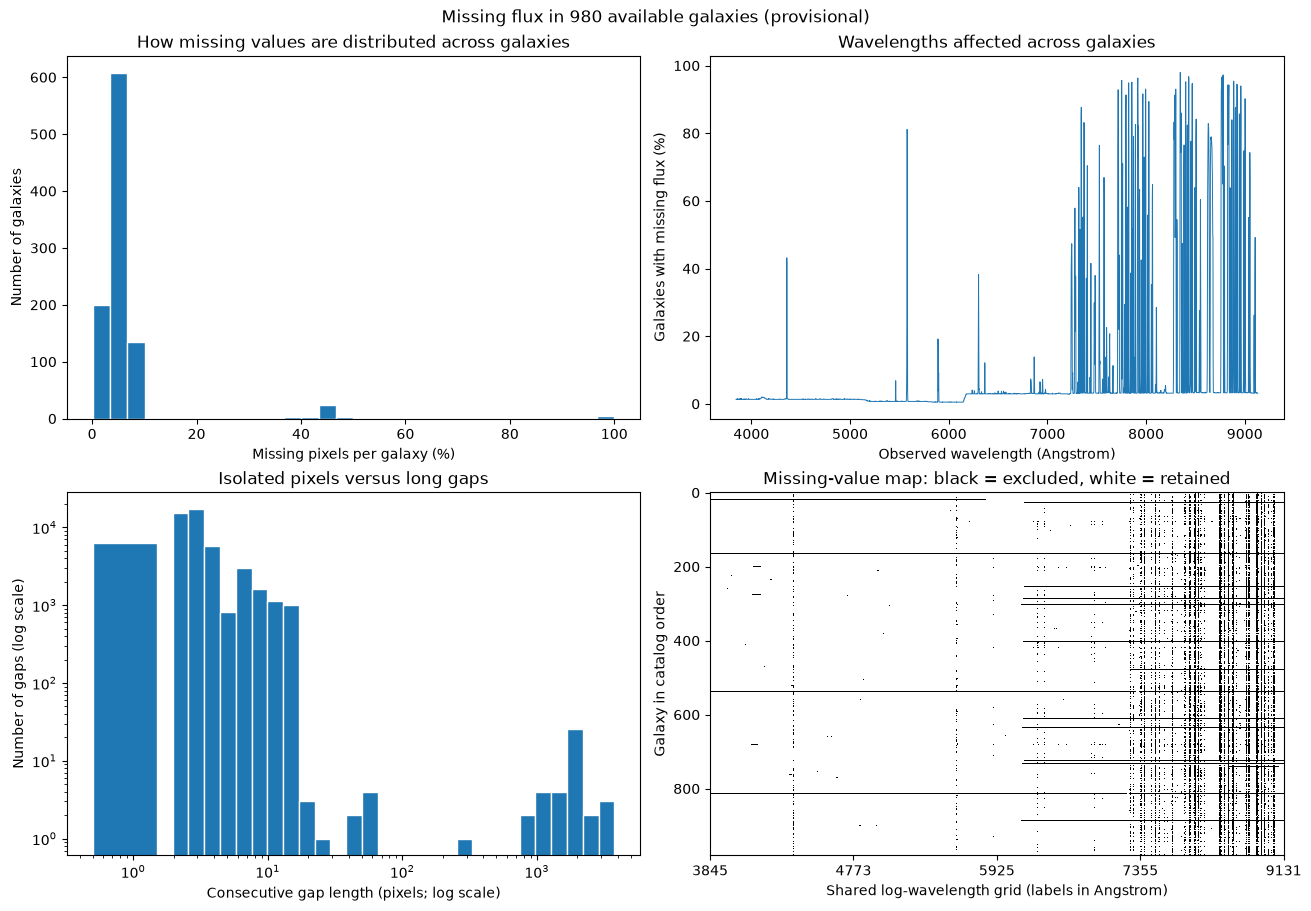

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
axes[0, 0].hist(missing_by_galaxy["missing_percent"], bins=30, edgecolor="white")
axes[0, 0].set(xlabel="Missing pixels per galaxy (%)", ylabel="Number of galaxies")
axes[0, 0].set_title("How missing values are distributed across galaxies")

axes[0, 1].plot(common_wavelength_angstrom, missing_by_wavelength["missing_percent"], linewidth=0.7)
axes[0, 1].set(xlabel="Observed wavelength (Angstrom)", ylabel="Galaxies with missing flux (%)")
axes[0, 1].set_title("Wavelengths affected across galaxies")

if not missing_gaps.empty:
    longest = int(missing_gaps["length_pixels"].max())
    bins = np.unique(np.r_[0.5, np.geomspace(1.5, max(longest + 0.5, 2), 30)])
    axes[1, 0].hist(missing_gaps["length_pixels"], bins=bins, edgecolor="white")
    axes[1, 0].set_xscale("log")
    axes[1, 0].set_yscale("log")
axes[1, 0].set(xlabel="Consecutive gap length (pixels; log scale)", ylabel="Number of gaps (log scale)")
axes[1, 0].set_title("Isolated pixels versus long gaps")

image = axes[1, 1].imshow(missing_matrix, aspect="auto", interpolation="nearest",
                           cmap="Greys", vmin=0, vmax=1)
tick_positions = np.linspace(0, n_shared_pixels - 1, 5).astype(int)
axes[1, 1].set_xticks(tick_positions, [f"{common_wavelength_angstrom[i]:.0f}" for i in tick_positions])
axes[1, 1].set(xlabel="Shared log-wavelength grid (labels in Angstrom)", ylabel="Galaxy in catalog order")
axes[1, 1].set_title("Missing-value map: black = excluded, white = retained")
fig.suptitle(f"Missing flux in {len(analysis_ids):,} available galaxies (provisional)")
plt.show()

## Check the 10% missingness and 3-pixel gap proposal

A galaxy is below the missingness threshold if fewer than 10% of its shared-range pixels are excluded. A gap is eligible for the proposed interpolation only if it contains at most 3 consecutive missing pixels and has valid measurements on both sides. Check these conditions separately; low total missingness does not imply short gaps. This cell only investigates the rule and does not remove galaxies or interpolate flux.

In [7]:
MISSING_PERCENT_LIMIT = 10.0
MAX_INTERPOLATION_GAP = 3

interpolation_check = missing_by_galaxy.copy()
edge_gaps_by_galaxy = missing_gaps.groupby("specObjID")["touches_edge"].any()
interpolation_check["has_edge_gap"] = edge_gaps_by_galaxy.reindex(interpolation_check.index, fill_value=False).astype(bool)
interpolation_check["below_10_percent"] = interpolation_check["missing_percent"] < MISSING_PERCENT_LIMIT
interpolation_check["all_gaps_at_most_3"] = interpolation_check["longest_gap_pixels"] <= MAX_INTERPOLATION_GAP
interpolation_check["short_interior_gaps_only"] = (
    interpolation_check["all_gaps_at_most_3"] & ~interpolation_check["has_edge_gap"]
)
low_missing = interpolation_check["below_10_percent"]
short_only = low_missing & interpolation_check["short_interior_gaps_only"]
needs_other_treatment = low_missing & ~interpolation_check["short_interior_gaps_only"]
n_checked = len(interpolation_check)
n_low = int(low_missing.sum())

rule_check_summary = pd.DataFrame([
    {"category": "Below 10%; all gaps interior and at most 3 pixels", "galaxies": int(short_only.sum())},
    {"category": "Below 10%; has longer gaps or edge gaps", "galaxies": int(needs_other_treatment.sum())},
    {"category": "10% or more missing", "galaxies": int((~low_missing).sum())},
])
rule_check_summary["percent_of_checked"] = 100 * rule_check_summary["galaxies"] / n_checked

below_limit_summary = pd.DataFrame([
    {"condition_among_galaxies_below_10_percent": f"Longest gap at most {length} pixels",
     "galaxies": int((low_missing & (interpolation_check["longest_gap_pixels"] <= length)).sum())}
    for length in [1, 2, 3, 5, 10, 20, 50]
])
below_limit_summary["percent_of_below_10_percent"] = 100 * below_limit_summary["galaxies"] / max(n_low, 1)

low_ids = set(interpolation_check.index[low_missing])
gaps_below_limit = missing_gaps.loc[missing_gaps["specObjID"].isin(low_ids)].copy()
can_interpolate = ((gaps_below_limit["length_pixels"] <= MAX_INTERPOLATION_GAP)
                   & ~gaps_below_limit["touches_edge"])
missing_pixels_below_limit = int(gaps_below_limit["length_pixels"].sum())
eligible_pixels = int(gaps_below_limit.loc[can_interpolate, "length_pixels"].sum())

print(f"Checked {n_checked:,}/{N_GALAXIES:,} galaxies (provisional).")
print(f"Below 10% missing: {n_low:,}/{n_checked:,} ({100*n_low/n_checked:.2f}%).")
print(f"Of those, {int(short_only.sum()):,}/{n_low:,} have only interior gaps of up to 3 pixels.")
print(f"Of those, {int((low_missing & interpolation_check['has_edge_gap']).sum()):,} have a missing edge pixel.")
print(f"A 3-pixel interior-gap rule could fill {eligible_pixels:,}/{missing_pixels_below_limit:,} "
      f"missing pixels ({100*eligible_pixels/max(missing_pixels_below_limit,1):.2f}%) among galaxies below 10% missing.")
print(f"The remaining {missing_pixels_below_limit-eligible_pixels:,} missing pixels would need another treatment.")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 65):
    display(rule_check_summary.round(3))
    display(below_limit_summary.round(3))
    print("Longest gaps among galaxies below 10% missing:")
    display(interpolation_check.loc[low_missing].sort_values("longest_gap_pixels", ascending=False).head(10).round(3))
print("No additional galaxies have been removed, and no flux values have been filled.")

Checked 980/5,000 galaxies (provisional).
Below 10% missing: 939/980 (95.82%).
Of those, 19/939 have only interior gaps of up to 3 pixels.
Of those, 0 have a missing edge pixel.
A 3-pixel interior-gap rule could fill 87,918/174,112 missing pixels (50.50%) among galaxies below 10% missing.
The remaining 86,194 missing pixels would need another treatment.


,category,galaxies,percent_of_checked
0,Below 10%; all gaps interior and at most 3 pixels,19,1.939
1,Below 10%; has longer gaps or edge gaps,920,93.878
2,10% or more missing,41,4.184


,condition_among_galaxies_below_10_percent,galaxies,percent_of_below_10_percent
0,Longest gap at most 1 pixels,1,0.106
1,Longest gap at most 2 pixels,4,0.426
2,Longest gap at most 3 pixels,19,2.023
3,Longest gap at most 5 pixels,76,8.094
4,Longest gap at most 10 pixels,226,24.068
5,Longest gap at most 20 pixels,931,99.148
6,Longest gap at most 50 pixels,934,99.468


Longest gaps among galaxies below 10% missing:


,missing_pixels,missing_percent,n_gaps,longest_gap_pixels,has_edge_gap,below_10_percent,all_gaps_at_most_3,short_interior_gaps_only
specObjID,,,,,,,,
5148983084918790144,371,9.875,23,322,False,True,False,False
9579385512332122112,278,7.400,64,58,False,True,False,False
2828282346388613120,288,7.666,66,56,False,True,False,False
1876897467362994176,192,5.110,40,54,False,True,False,False
2725826559008073728,246,6.548,60,54,False,True,False,False
686821792534259712,158,4.205,34,41,False,True,False,False
5334748874023393280,185,4.924,52,24,False,True,False,False
5491087883577350144,266,7.080,70,22,False,True,False,False
2341892753157285888,107,2.848,35,20,False,True,False,False


No additional galaxies have been removed, and no flux values have been filled.


## Prepare the regression baseline

Keep galaxies with **less than 10% missing shared-range pixels**, then split them **70%/15%/15%** with seed 42. Remove wavelength columns missing in **more than 50% of training galaxies**, applying the same column selection to all sets. Fill remaining entries with training-set medians and append missing-value indicators. These thresholds are project choices. No interpolation, scaling, or regression fitting is performed. This remains provisional until the download is complete.

[Splitting documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) and [imputation documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).

In [6]:
GALAXY_MISSING_LIMIT = 0.10
COLUMN_MISSING_LIMIT = 0.50
if common_loglam is None or not spectrum_bounds["on_shared_grid"].all():
    raise RuntimeError("Run the shared-range and filtering cells first.")

bounds_by_id = spectrum_bounds.set_index("specObjID")
prepared_ids = [str(value) for value in checked_galaxies["specObjID"]]
flux_rows = []
for spec_id in prepared_ids:
    start = int(common_grid_positions[0]) - int(bounds_by_id.loc[spec_id, "start_grid_position"])
    stop = start + len(common_grid_positions)
    native_flux = filtered_flux[spec_id]
    if start < 0 or stop > len(native_flux):
        raise ValueError(f"Grid and flux disagree for {spec_id}; rerun preparation.")
    flux_rows.append(native_flux[start:stop])

feature_wavelengths = pd.DataFrame({
    "feature": [f"flux_loglam_{value:.4f}" for value in common_loglam],
    "grid_position": common_grid_positions, "loglam": common_loglam,
    "wavelength_angstrom": common_wavelength_angstrom,
}).set_index("feature")
X_shared = pd.DataFrame(np.stack(flux_rows),
    index=pd.Index(prepared_ids, name="specObjID"), columns=feature_wavelengths.index)
if np.isinf(X_shared.to_numpy()).any():
    raise ValueError("Infinite flux remains; rerun the exclusion cell.")
row_missing_fraction = X_shared.isna().mean(axis=1)
galaxy_selection = pd.DataFrame({"missing_percent": 100 * row_missing_fraction,
    "retained": row_missing_fraction < GALAXY_MISSING_LIMIT})
X = X_shared.loc[galaxy_selection["retained"]].copy()
y_model = y.loc[X.index, TARGET_COLUMNS].copy()
assert X.index.is_unique and X.index.equals(y_model.index)
assert np.isfinite(y_model.to_numpy(dtype=float)).all()
if len(X) < 10:
    raise RuntimeError("Too few galaxies to split.")
print(f"Available: {len(X_shared):,}/{N_GALAXIES:,}; retained: {len(X):,}; excluded: {len(X_shared)-len(X):,}")
print(f"Aligned flux X: {X.shape}; matching targets y_model: {y_model.shape}")
if len(X_shared) < N_GALAXIES:
    print("PROVISIONAL: rerun coverage, filtering, and baseline cells after the download.")

Available: 980/5,000; retained: 939; excluded: 41
Aligned flux X: (939, 3757); matching targets y_model: (939, 4)
PROVISIONAL: rerun coverage, filtering, and baseline cells after the download.


In [7]:
from sklearn.model_selection import train_test_split

train_ids, holdout_ids = train_test_split(X.index.to_numpy(), test_size=0.30, random_state=SEED)
validation_ids, test_ids = train_test_split(holdout_ids, test_size=0.50, random_state=SEED)
X_train_raw, X_validation_raw, X_test_raw = [X.loc[ids].copy() for ids in [train_ids, validation_ids, test_ids]]
y_train, y_validation, y_test = [y_model.loc[ids].copy() for ids in [train_ids, validation_ids, test_ids]]

training_column_missing = X_train_raw.isna().mean(axis=0)
kept_wavelength_columns = training_column_missing.index[training_column_missing <= COLUMN_MISSING_LIMIT]
dropped_wavelength_columns = training_column_missing.index[training_column_missing > COLUMN_MISSING_LIMIT]
if len(kept_wavelength_columns) == 0:
    raise RuntimeError("No wavelength columns passed the training-set missingness threshold.")
X_train_flux, X_validation_flux, X_test_flux = [
    frame.loc[:, kept_wavelength_columns].copy() for frame in [X_train_raw, X_validation_raw, X_test_raw]]
feature_wavelengths["training_missing_percent"] = 100 * training_column_missing
feature_wavelengths["retained"] = feature_wavelengths.index.isin(kept_wavelength_columns)
baseline_missingness = pd.DataFrame([
    {"split": name, "galaxies": len(before), "wavelengths_before": before.shape[1],
     "wavelengths_retained": after.shape[1],
     "missing_percent_before": 100 * before.isna().to_numpy().mean(),
     "missing_percent_after_column_filter": 100 * after.isna().to_numpy().mean(),
     "remaining_missing_values": int(after.isna().to_numpy().sum())}
    for name, before, after in [("train", X_train_raw, X_train_flux),
        ("validation", X_validation_raw, X_validation_flux), ("test", X_test_raw, X_test_flux)]
]).set_index("split")
print(f"Wavelength columns removed: {len(dropped_wavelength_columns):,}/{X.shape[1]:,}")
with pd.option_context("display.max_columns", None):
    display(baseline_missingness.round(3))

Wavelength columns removed: 182/3,757


,galaxies,wavelengths_before,wavelengths_retained,missing_percent_before,missing_percent_after_column_filter,remaining_missing_values
split,,,,,,
train,657,3757,3575,4.926,1.297,30462
validation,141,3757,3575,4.959,1.279,6449
test,141,3757,3575,4.957,1.309,6596


In [8]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median", add_indicator=True)
X_train = pd.DataFrame(imputer.fit_transform(X_train_flux), index=X_train_flux.index,
    columns=imputer.get_feature_names_out())
X_validation = pd.DataFrame(imputer.transform(X_validation_flux), index=X_validation_flux.index,
    columns=imputer.get_feature_names_out())
X_test = pd.DataFrame(imputer.transform(X_test_flux), index=X_test_flux.index,
    columns=imputer.get_feature_names_out())

# Verify disjoint sets, target alignment, preserved measurements, and indicators.
assert not (set(train_ids) & set(validation_ids) or set(train_ids) & set(test_ids)
    or set(validation_ids) & set(test_ids))
assert len(train_ids) + len(validation_ids) + len(test_ids) == len(X)
for completed, raw, targets in [(X_train, X_train_flux, y_train),
        (X_validation, X_validation_flux, y_validation), (X_test, X_test_flux, y_test)]:
    assert completed.index.equals(targets.index)
    assert np.isfinite(completed.to_numpy()).all()
    observed = raw.notna().to_numpy()
    np.testing.assert_array_equal(completed.iloc[:, :raw.shape[1]].to_numpy()[observed],
        raw.to_numpy()[observed])
    np.testing.assert_array_equal(completed.iloc[:, raw.shape[1]:].to_numpy(),
        raw.isna().to_numpy()[:, imputer.indicator_.features_].astype(float))
prepared_shapes = pd.DataFrame([
    {"split": name, "galaxies": len(features), "flux_features": len(kept_wavelength_columns),
     "missing_indicators": len(imputer.indicator_.features_),
     "total_input_features": features.shape[1], "targets": targets.shape[1],
     "remaining_missing_values": int(features.isna().to_numpy().sum())}
    for name, features, targets in [("train", X_train, y_train),
        ("validation", X_validation, y_validation), ("test", X_test, y_test)]
]).set_index("split")
with pd.option_context("display.max_columns", None):
    display(prepared_shapes)
print("Imputation uses training flux only. No regression model has been fitted.")

,galaxies,flux_features,missing_indicators,total_input_features,targets,remaining_missing_values
split,,,,,,
train,657,3575,994,4569,4,0
validation,141,3575,994,4569,4,0
test,141,3575,994,4569,4,0


Imputation uses training flux only. No regression model has been fitted.


### Save the prepared inputs

Save finite input matrices and matching targets, split IDs, wavelength selection, fitted imputer, and configuration separately from the original files. Indicators correspond to retained wavelength columns with missing training values. Existing prepared outputs are replaced when these cells are rerun.

In [9]:
import json
import joblib

PREPARED_DIR = DATA_DIR / "prepared_baseline"
PREPARED_DIR.mkdir(exist_ok=True)
np.savez_compressed(PREPARED_DIR / "regression_inputs.npz",
    X_train=X_train.to_numpy(), X_validation=X_validation.to_numpy(), X_test=X_test.to_numpy(),
    y_train=y_train.to_numpy(), y_validation=y_validation.to_numpy(), y_test=y_test.to_numpy(),
    train_ids=np.asarray(train_ids, dtype=str), validation_ids=np.asarray(validation_ids, dtype=str),
    test_ids=np.asarray(test_ids, dtype=str), feature_names=np.asarray(X_train.columns, dtype=str),
    target_names=np.asarray(TARGET_COLUMNS, dtype=str))
joblib.dump(imputer, PREPARED_DIR / "median_imputer.joblib")
feature_wavelengths.to_csv(PREPARED_DIR / "wavelength_selection.csv")
galaxy_selection.to_csv(PREPARED_DIR / "galaxy_selection.csv")
split_membership = pd.concat([pd.DataFrame({"specObjID": ids, "split": name})
    for name, ids in [("train", train_ids), ("validation", validation_ids), ("test", test_ids)]], ignore_index=True)
split_membership.to_csv(PREPARED_DIR / "split_membership.csv", index=False)
baseline_missingness.to_csv(PREPARED_DIR / "missingness_summary.csv")
prepared_shapes.to_csv(PREPARED_DIR / "prepared_shapes.csv")
config = {"data_release": DATA_RELEASE, "requested_galaxies": N_GALAXIES,
    "available_galaxies": len(X_shared), "retained_galaxies": len(X),
    "provisional": len(X_shared) < N_GALAXIES, "seed": SEED,
    "galaxy_missing_fraction_exclude_at_or_above": GALAXY_MISSING_LIMIT,
    "training_column_missing_fraction_exclude_above": COLUMN_MISSING_LIMIT,
    "nominal_split_fractions": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "target_columns": TARGET_COLUMNS, "excluded_and_flags": EXCLUDE_AND_FLAGS,
    "shared_grid_start": int(common_grid_positions[0]), "shared_grid_end": int(common_grid_positions[-1]),
    "loglam_step": LOG_STEP, "imputation": "training-column median", "add_missing_indicators": True,
    "scaled": False, "interpolated": False, "regression_fitted": False}
(PREPARED_DIR / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"Saved prepared baseline inputs to {PREPARED_DIR}")

Saved prepared baseline inputs to data\dr17_5000\prepared_baseline


# Linear regression

In [2]:
# Inputs: prepared training flux values and missing-value indicators.
X_redshift = X_train.copy()

# Target: the redshift of each training galaxy.
y_redshift = y_train["z"].copy()

print("X_redshift:", X_redshift.shape)
print("y_redshift:", y_redshift.shape)

X_redshift: (657, 4569)
y_redshift: (657,)


In [2]:
from sklearn.linear_model import LinearRegression

# Use the same existing split for all four targets.
print("Data split: 70% training / 15% validation / 15% test (seed 42)")
print(f"Training: {len(X_train)} galaxies")
print(f"Validation: {len(X_validation)} galaxies")
print(f"Test: {len(X_test)} galaxies")

linear_models = {}
for target in ["z", "cModelMag_g", "cModelMag_r", "cModelMag_i"]:
    # Create a new model for each target; do not overwrite a previously fitted model.
    model = LinearRegression()
    model.fit(X_train, y_train[target])
    linear_models[target] = model
    print(f"Fitted linear regression for {target}.", flush=True)

redshift_model = linear_models["z"]
g_magnitude_model = linear_models["cModelMag_g"]
r_magnitude_model = linear_models["cModelMag_r"]
i_magnitude_model = linear_models["cModelMag_i"]

Data split: 70% training / 15% validation / 15% test (seed 42)
Training: 3359 galaxies
Validation: 720 galaxies
Test: 720 galaxies


Fitted linear regression for z.


Fitted linear regression for cModelMag_g.


Fitted linear regression for cModelMag_r.


Fitted linear regression for cModelMag_i.


In [3]:
from sklearn.metrics import mean_absolute_error

# Evaluate each fitted model on the validation galaxies.
assert X_validation.index.equals(y_validation.index)
validation_predictions = pd.DataFrame(index=X_validation.index)
mae_rows = []
for target in ["z", "cModelMag_g", "cModelMag_r", "cModelMag_i"]:
    predictions = linear_models[target].predict(X_validation)
    validation_predictions[target] = predictions
    mae_rows.append({
        "target": target,
        "validation_MAE": mean_absolute_error(y_validation[target], predictions),
        "validation_galaxies": len(y_validation),
        "unit": "dimensionless" if target == "z" else "mag",
    })

validation_mae = pd.DataFrame(mae_rows).set_index("target")
display(validation_mae)

,validation_MAE,validation_galaxies,unit
target,,,
z,0.241816,720,dimensionless
cModelMag_g,1.533109,720,mag
cModelMag_r,1.251973,720,mag
cModelMag_i,1.168410,720,mag


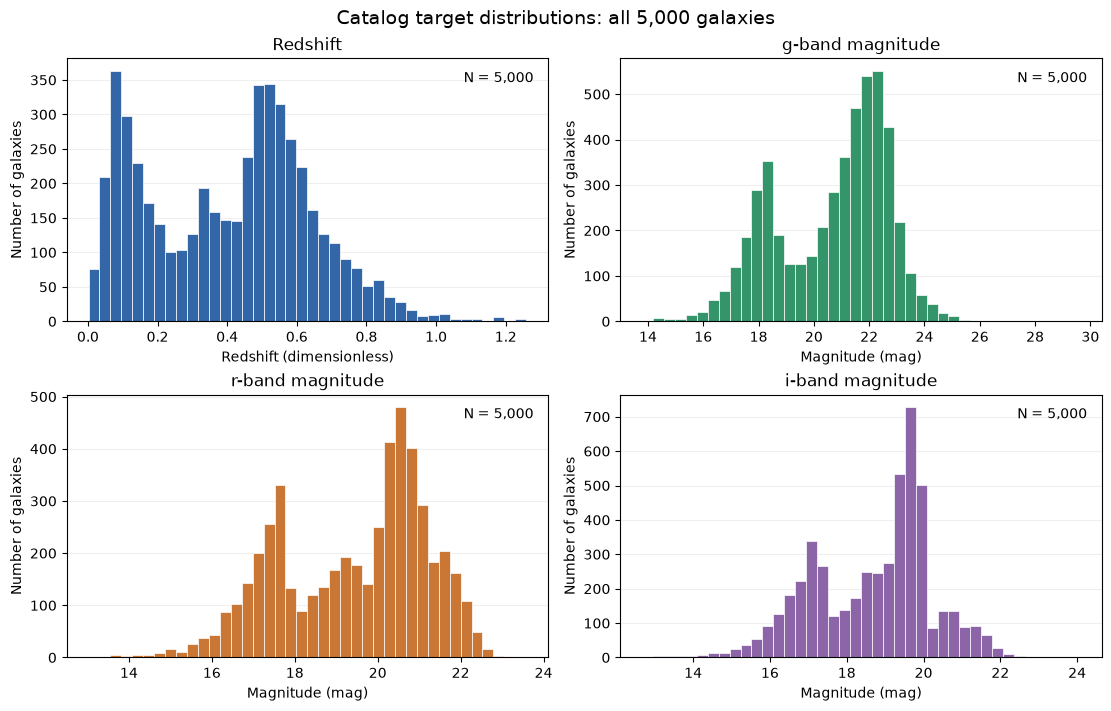

In [2]:
import matplotlib.pyplot as plt

# All catalog galaxies, including those excluded from model training.
target_labels = {
    "z": "Redshift", "cModelMag_g": "g-band magnitude",
    "cModelMag_r": "r-band magnitude", "cModelMag_i": "i-band magnitude",
}
colors = ["#3366A6", "#34946A", "#CA7634", "#8B65A8"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, (target, label), color in zip(axes.flat, target_labels.items(), colors):
    values = galaxies[target].to_numpy(dtype=float)
    ax.hist(values, bins=40, color=color, edgecolor="white", linewidth=0.5)
    ax.set_title(label)
    ax.set_xlabel("Redshift (dimensionless)" if target == "z" else "Magnitude (mag)")
    ax.set_ylabel("Number of galaxies")
    ax.text(0.97, 0.95, f"N = {len(values):,}", transform=ax.transAxes,
            ha="right", va="top")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(f"Catalog target distributions: all {len(galaxies):,} galaxies", fontsize=14)
Path("build").mkdir(exist_ok=True)
fig.savefig("build/target_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

# Random Forest Regression

Tune each target in this order: number of trees, feature sampling, then minimum leaf size. At each stage, fix the best setting from the previous stage, selected by validation MAE. Keep the existing training/validation split; do not evaluate the test set. Other settings remain at their defaults.

The helper in `rf_tuning.py` saves every completed trial, model, and training time. It reuses trials when data and settings match. In stage 1 it adds trees to the same forest to avoid repeating earlier training. The reported training time is cumulative when trees are added.

The Windows task `SDSS-RandomForest-Tuning` runs this search independently of SSH using `run_rf_tuning.py`. Progress is in `data/dr17_5000/random_forest_tuning/background.log` and `background_status.json`. After it finishes, rerunning these cells reloads cached trials and selected models. Avoid starting another search while the background task is running.

In [2]:
from pathlib import Path
from rf_tuning import SequentialRandomForestTuner

RF_TREE_COUNTS = [100, 200, 400]
RF_FEATURE_FRACTIONS = [1.0, 0.5, 0.3]
RF_LEAF_SIZES = [1, 3, 5, 10]
rf_tuner = SequentialRandomForestTuner(
    X_train, y_train, X_validation, y_validation,
    output_dir=Path("data/dr17_5000/random_forest_tuning"),
    random_state=42, n_jobs=8,
)
print("Results directory:", rf_tuner.output_dir)
print(f"Training: {len(X_train):,}; validation: {len(X_validation):,}; inputs: {X_train.shape[1]:,}")

Results directory: data\dr17_5000\random_forest_tuning\4b3527bb672c710d
Training: 3,359; validation: 720; inputs: 2,717


## 1. Number of trees

Compare 100, 200, and 400 trees. Keep all features available at each split, `min_samples_leaf=1`, and no fixed maximum depth. Select a tree count separately for each target.

In [3]:
rf_tree_count_results = rf_tuner.tune_tree_counts(RF_TREE_COUNTS)
best_tree_counts = rf_tuner.best_per_target(rf_tree_count_results)["n_estimators"].astype(int).to_dict()
display(rf_tree_count_results.drop(columns="model_file"))
print("Selected tree counts:", best_tree_counts)

CACHED z: trees=100, max_features=1, min_samples_leaf=1; MAE=0.043322


CACHED z: trees=200, max_features=1, min_samples_leaf=1; MAE=0.043110


CACHED z: trees=400, max_features=1, min_samples_leaf=1; MAE=0.042771


CACHED cModelMag_g: trees=100, max_features=1, min_samples_leaf=1; MAE=0.503060


START cModelMag_g: trees=200, max_features=1, min_samples_leaf=1


DONE cModelMag_g: trees=200, max_features=1, min_samples_leaf=1; MAE=0.500982; training=103.8s


... (12 outputs left out)

START cModelMag_i: trees=400, max_features=1, min_samples_leaf=1


DONE cModelMag_i: trees=400, max_features=1, min_samples_leaf=1; MAE=0.297089; training=221.4s


,target,n_estimators,max_features,min_samples_leaf,validation_MAE,training_seconds,incremental_fit_seconds
0,z,100,1.0,1,0.043322,50.476672,50.476672
1,z,200,1.0,1,0.043110,101.345532,50.868860
2,z,400,1.0,1,0.042771,196.225538,94.880006
3,cModelMag_g,100,1.0,1,0.503060,51.230985,51.230985
4,cModelMag_g,200,1.0,1,0.500982,103.786373,52.555388
5,cModelMag_g,400,1.0,1,0.501071,202.268189,98.481816
6,cModelMag_r,100,1.0,1,0.315432,49.590791,49.590791
7,cModelMag_r,200,1.0,1,0.314209,102.263450,52.672658
8,cModelMag_r,400,1.0,1,0.314249,196.641066,94.377616
9,cModelMag_i,100,1.0,1,0.299259,53.987195,53.987195


Selected tree counts: {'z': 400, 'cModelMag_i': 400, 'cModelMag_r': 200, 'cModelMag_g': 200}


## 2. Feature sampling

Fix each target's selected tree count. Compare 100%, 50%, and 30% of input columns at each split, keeping `min_samples_leaf=1` and no fixed maximum depth.

In [4]:
rf_feature_results = rf_tuner.tune_feature_fractions(RF_FEATURE_FRACTIONS, best_tree_counts)
best_feature_fractions = rf_tuner.best_per_target(rf_feature_results)["max_features"].to_dict()
display(rf_feature_results.drop(columns="model_file"))
print("Selected feature fractions:", best_feature_fractions)

CACHED z: trees=400, max_features=1, min_samples_leaf=1; MAE=0.042771


START z: trees=400, max_features=0.5, min_samples_leaf=1


DONE z: trees=400, max_features=0.5, min_samples_leaf=1; MAE=0.042315; training=102.8s


START z: trees=400, max_features=0.3, min_samples_leaf=1


DONE z: trees=400, max_features=0.3, min_samples_leaf=1; MAE=0.042249; training=62.0s


CACHED cModelMag_g: trees=200, max_features=1, min_samples_leaf=1; MAE=0.500982


... (12 outputs left out)

START cModelMag_i: trees=400, max_features=0.3, min_samples_leaf=1


DONE cModelMag_i: trees=400, max_features=0.3, min_samples_leaf=1; MAE=0.297558; training=71.8s


,target,n_estimators,max_features,min_samples_leaf,validation_MAE,training_seconds,incremental_fit_seconds
0,z,400,1.0,1,0.042771,196.225538,94.880006
1,z,400,0.5,1,0.042315,102.809356,102.809356
2,z,400,0.3,1,0.042249,62.032265,62.032265
3,cModelMag_g,200,1.0,1,0.500982,103.786373,52.555388
4,cModelMag_g,200,0.5,1,0.500847,51.898181,51.898181
5,cModelMag_g,200,0.3,1,0.499563,37.634711,37.634711
6,cModelMag_r,200,1.0,1,0.314209,102.263450,52.672658
7,cModelMag_r,200,0.5,1,0.316035,55.248554,55.248554
8,cModelMag_r,200,0.3,1,0.316020,38.203368,38.203368
9,cModelMag_i,400,1.0,1,0.297089,221.399958,112.511181


Selected feature fractions: {'z': 0.3, 'cModelMag_i': 1.0, 'cModelMag_r': 1.0, 'cModelMag_g': 0.3}


## 3. Minimum leaf size

Fix each target's selected tree count and feature fraction. Compare minimum leaf sizes of 1, 3, 5, and 10. Select the best setting by validation MAE.

In [5]:
rf_leaf_results = rf_tuner.tune_leaf_sizes(RF_LEAF_SIZES, best_tree_counts, best_feature_fractions)
rf_best_results = rf_tuner.best_per_target(rf_leaf_results).loc[y_train.columns]
rf_models = rf_tuner.load_selected_models(rf_best_results)
display(rf_leaf_results.drop(columns="model_file"))
print("Final selected settings and validation MAE:")
display(rf_best_results[["n_estimators", "max_features", "min_samples_leaf", "validation_MAE", "training_seconds"]])
print("Selected forests are stored in rf_models. The test set has not been evaluated.")

CACHED z: trees=400, max_features=0.3, min_samples_leaf=1; MAE=0.042249


START z: trees=400, max_features=0.3, min_samples_leaf=3


DONE z: trees=400, max_features=0.3, min_samples_leaf=3; MAE=0.042421; training=57.8s


START z: trees=400, max_features=0.3, min_samples_leaf=5


DONE z: trees=400, max_features=0.3, min_samples_leaf=5; MAE=0.042584; training=51.5s


START z: trees=400, max_features=0.3, min_samples_leaf=10


... (22 outputs left out)

,target,n_estimators,max_features,min_samples_leaf,validation_MAE,training_seconds,incremental_fit_seconds
0,z,400,0.3,1,0.042249,62.032265,62.032265
1,z,400,0.3,3,0.042421,57.804117,57.804117
2,z,400,0.3,5,0.042584,51.469241,51.469241
3,z,400,0.3,10,0.043185,38.770209,38.770209
4,cModelMag_g,200,0.3,1,0.499563,37.634711,37.634711
5,cModelMag_g,200,0.3,3,0.502539,24.734172,24.734172
6,cModelMag_g,200,0.3,5,0.503086,28.282136,28.282136
7,cModelMag_g,200,0.3,10,0.503307,22.073220,22.073220
8,cModelMag_r,200,1.0,1,0.314209,102.263450,52.672658
9,cModelMag_r,200,1.0,3,0.314553,91.225573,91.225573


Final selected settings and validation MAE:


,n_estimators,max_features,min_samples_leaf,validation_MAE,training_seconds
target,,,,,
z,400,0.3,1,0.042249,62.032265
cModelMag_g,200,0.3,1,0.499563,37.634711
cModelMag_r,200,1.0,1,0.314209,102.263450
cModelMag_i,400,1.0,1,0.297089,221.399958


Selected forests are stored in rf_models. The test set has not been evaluated.


# Principal Component Analysis

Apply PCA to the prepared, median-filled **flux columns only**. Missing-value indicators are not spectral fluxes and are kept separate. Load the existing saved split so this section can run independently. Fit the mean and component directions using training galaxies only; apply the same transformation to validation galaxies. Flux columns are centred but not standardized to unit variance, so PCA describes variation in the original flux units. Prediction targets and the test set are not used.

[scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

In [1]:
from pathlib import Path
import hashlib
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

PCA_INPUT_PATH = Path("data/dr17_5000/prepared_baseline/regression_inputs.npz")
PCA_OUTPUT_DIR = Path("data/dr17_5000/pca")
PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
Path("build").mkdir(exist_ok=True)

with np.load(PCA_INPUT_PATH, allow_pickle=False) as prepared:
    pca_feature_names = prepared["feature_names"].astype(str)
    pca_flux_mask = np.char.startswith(pca_feature_names, "flux_loglam_")
    pca_flux_columns = pca_feature_names[pca_flux_mask]
    pca_train_ids = prepared["train_ids"].astype(str)
    pca_validation_ids = prepared["validation_ids"].astype(str)
    pca_train_flux = pd.DataFrame(
        prepared["X_train"][:, pca_flux_mask],
        index=pd.Index(pca_train_ids, name="specObjID"),
        columns=pca_flux_columns,
    )
    pca_validation_flux = pd.DataFrame(
        prepared["X_validation"][:, pca_flux_mask],
        index=pd.Index(pca_validation_ids, name="specObjID"),
        columns=pca_flux_columns,
    )

assert pca_flux_mask.any()
assert pca_train_flux.columns.equals(pca_validation_flux.columns)
assert set(pca_train_ids).isdisjoint(pca_validation_ids)
assert np.isfinite(pca_train_flux.to_numpy()).all()
assert np.isfinite(pca_validation_flux.to_numpy()).all()
print(f"Training galaxies: {len(pca_train_flux):,}")
print(f"Validation galaxies: {len(pca_validation_flux):,}")
print(f"Flux columns: {len(pca_flux_columns):,}")
print(f"Missing indicators kept separate: {(~pca_flux_mask).sum():,}")

Training galaxies: 3,359
Validation galaxies: 720
Flux columns: 1,902
Missing indicators kept separate: 815


## Fit PCA and measure explained variance

Fit all components once using full singular value decomposition. The component weights are in `pca_full.components_`, the training column means in `pca_full.mean_`, and the variance fractions in `pca_full.explained_variance_ratio_`. These variances describe differences between galaxies, not measurement uncertainties. Use **95% of training variance** as an initial compression threshold; this is not a statement about prediction accuracy.

In [2]:
pca_started = time.perf_counter()
pca_full = PCA(svd_solver="full", whiten=False)
with threadpool_limits(limits=8):
    pca_full.fit(pca_train_flux)
pca_fit_seconds = time.perf_counter() - pca_started

pca_cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
pca_variance_table = pd.DataFrame({
    "component": np.arange(1, pca_full.n_components_ + 1),
    "variance": pca_full.explained_variance_,
    "variance_fraction": pca_full.explained_variance_ratio_,
    "cumulative_fraction": pca_cumulative_variance,
})
pca_thresholds = [0.90, 0.95, 0.99, 0.999]
pca_component_counts = [
    int(np.searchsorted(pca_cumulative_variance, threshold) + 1)
    for threshold in pca_thresholds
]
pca_threshold_summary = pd.DataFrame({
    "requested_variance_percent": np.array(pca_thresholds) * 100,
    "components_needed": pca_component_counts,
    "retained_variance_percent": [
        100 * pca_cumulative_variance[count - 1]
        for count in pca_component_counts
    ],
})
PCA_RETAINED_VARIANCE = 0.95
pca_n_components = int(
    np.searchsorted(pca_cumulative_variance, PCA_RETAINED_VARIANCE) + 1
)
assert np.isfinite(pca_full.components_).all()
assert np.all(np.diff(pca_full.explained_variance_) <= 0)
np.testing.assert_allclose(pca_cumulative_variance[-1], 1.0)
np.testing.assert_allclose(
    pca_full.mean_, pca_train_flux.mean(axis=0).to_numpy()
)
print(f"PCA fitted in {pca_fit_seconds:.1f} seconds.")
display(pca_threshold_summary.round(4))
display(pca_variance_table.head(10).round(6))

PCA fitted in 4.2 seconds.


,requested_variance_percent,components_needed,retained_variance_percent
0,90.0,1,92.7059
1,95.0,2,97.7974
2,99.0,8,99.0348
3,99.9,416,99.9001


,component,variance,variance_fraction,cumulative_fraction
0,1,239099.863924,0.927059,0.927059
1,2,13131.477466,0.050915,0.977974
2,3,1589.186980,0.006162,0.984136
3,4,573.681764,0.002224,0.986360
4,5,519.068853,0.002013,0.988373
5,6,244.575893,0.000948,0.989321
6,7,138.273605,0.000536,0.989857
7,8,126.745675,0.000491,0.990348
8,9,107.890779,0.000418,0.990767
9,10,96.044597,0.000372,0.991139


## Explained-variance plots

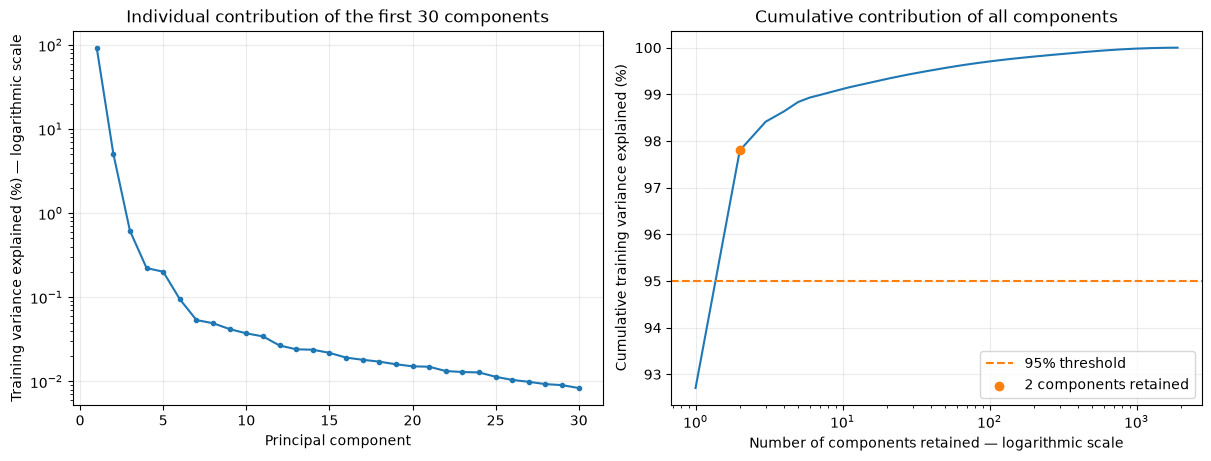

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
pca_first_components = pca_variance_table.head(30)
axes[0].plot(
    pca_first_components["component"],
    100 * pca_first_components["variance_fraction"],
    marker="o", markersize=3,
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Training variance explained (%) — logarithmic scale")
axes[0].set_title("Individual contribution of the first 30 components")

axes[1].plot(
    pca_variance_table["component"],
    100 * pca_variance_table["cumulative_fraction"],
)
axes[1].axhline(95, color="tab:orange", linestyle="--", label="95% threshold")
axes[1].scatter(
    [pca_n_components],
    [100 * pca_cumulative_variance[pca_n_components - 1]],
    color="tab:orange", zorder=3,
    label=f"{pca_n_components} components retained",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Number of components retained — logarithmic scale")
axes[1].set_ylabel("Cumulative training variance explained (%)")
axes[1].set_title("Cumulative contribution of all components")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.25)
fig.savefig("build/pca_explained_variance.png", dpi=200)
plt.show()

## Transform galaxies and save the PCA results

`X_train_pca` and `X_validation_pca` contain the retained component scores, with galaxy IDs preserved. The full fitted PCA is saved so other component counts can be investigated later without refitting. When reusing it, retain the first `pca_n_components` output columns. The original prepared inputs remain available.

In [4]:
pca_columns = [f"PC{number}" for number in range(1, pca_n_components + 1)]
with threadpool_limits(limits=8):
    X_train_pca = pd.DataFrame(
        pca_full.transform(pca_train_flux)[:, :pca_n_components],
        index=pca_train_flux.index, columns=pca_columns,
    )
    X_validation_pca = pd.DataFrame(
        pca_full.transform(pca_validation_flux)[:, :pca_n_components],
        index=pca_validation_flux.index, columns=pca_columns,
    )
    # All components should reconstruct the original prepared fluxes.
    pca_sample = pca_train_flux.iloc[:10]
    pca_reconstruction = pca_full.inverse_transform(
        pca_full.transform(pca_sample)
    )
np.testing.assert_allclose(
    pca_reconstruction, pca_sample.to_numpy(), rtol=1e-9, atol=1e-9
)
np.testing.assert_allclose(X_train_pca.mean(axis=0), 0, atol=1e-8)
assert np.isfinite(X_train_pca.to_numpy()).all()
assert np.isfinite(X_validation_pca.to_numpy()).all()
assert X_train_pca.index.equals(pca_train_flux.index)
assert X_validation_pca.index.equals(pca_validation_flux.index)

joblib.dump(pca_full, PCA_OUTPUT_DIR / "pca_full.joblib")
pca_variance_table.to_csv(PCA_OUTPUT_DIR / "explained_variance.csv", index=False)
pca_threshold_summary.to_csv(PCA_OUTPUT_DIR / "variance_thresholds.csv", index=False)
np.savez_compressed(
    PCA_OUTPUT_DIR / "pca_inputs.npz",
    X_train=X_train_pca.to_numpy(),
    X_validation=X_validation_pca.to_numpy(),
    train_ids=pca_train_ids, validation_ids=pca_validation_ids,
    component_names=np.asarray(pca_columns, dtype=str),
    flux_feature_names=pca_flux_columns,
    retained_components=np.asarray(pca_n_components),
)
with PCA_INPUT_PATH.open("rb") as source:
    pca_source_sha256 = hashlib.file_digest(source, "sha256").hexdigest()
pca_configuration = {
    "source": str(PCA_INPUT_PATH), "source_sha256": pca_source_sha256,
    "sklearn_version": sklearn.__version__,
    "fit_split": "train", "training_galaxies": len(pca_train_flux),
    "validation_galaxies": len(pca_validation_flux),
    "flux_features": len(pca_flux_columns),
    "missing_indicators_included": False,
    "centred": True, "standardized": False, "whiten": False,
    "svd_solver": "full", "requested_variance_fraction": PCA_RETAINED_VARIANCE,
    "retained_components": pca_n_components,
    "retained_variance_fraction": float(pca_cumulative_variance[pca_n_components - 1]),
    "test_set_used": False, "targets_used": False,
}
(PCA_OUTPUT_DIR / "configuration.json").write_text(
    json.dumps(pca_configuration, indent=2), encoding="utf-8"
)
print(f"Retained {pca_n_components} of {len(pca_flux_columns)} flux dimensions.")
print(f"X_train_pca: {X_train_pca.shape}")
print(f"X_validation_pca: {X_validation_pca.shape}")
display(X_train_pca.iloc[:10, :min(5, pca_n_components)].round(4))
print(f"Saved PCA model, component scores, and variance tables to {PCA_OUTPUT_DIR}.")

Retained 2 of 1902 flux dimensions.
X_train_pca: (3359, 2)
X_validation_pca: (720, 2)


,PC1,PC2
specObjID,,
5398852055199930368,-205.0794,0.7788
5286347002929764352,-153.1749,-2.3872
2572792125007620096,441.5697,-3.5298
7436605003845097472,-206.8683,0.0432
5185938780910278656,-205.9741,0.0783
7640366221863704576,-195.4547,0.2182
1998505934292281344,2161.3993,-15.0211
7651793721172973568,-204.5278,0.0042
10361903262328969216,-218.2593,0.4940


Saved PCA model, component scores, and variance tables to data\dr17_5000\pca.


## Galaxies in the first two principal components

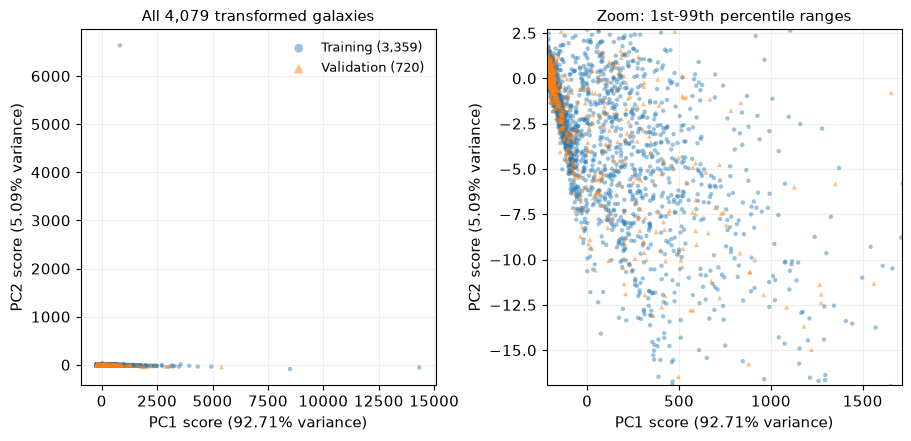

PCA fitted on training galaxies only; existing scores were used without refitting.
Both panels use the same galaxies. The right panel zooms the axis ranges.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

with np.load("data/dr17_5000/pca/pca_inputs.npz", allow_pickle=False) as scores:
    pca_plot_train = scores["X_train"][:, :2]
    pca_plot_validation = scores["X_validation"][:, :2]
pca_plot_variance = pd.read_csv("data/dr17_5000/pca/explained_variance.csv")
pca_plot_percent = 100 * pca_plot_variance["variance_fraction"].to_numpy()[:2]
pca_plot_all = np.vstack([pca_plot_train, pca_plot_validation])
pca_zoom_low, pca_zoom_high = np.quantile(pca_plot_all, [0.01, 0.99], axis=0)

with plt.rc_context({"font.size": 11, "axes.titlesize": 11}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), constrained_layout=True)
    for axis in axes:
        axis.scatter(
            pca_plot_train[:, 0], pca_plot_train[:, 1],
            s=10, alpha=0.45, edgecolors="none", color="tab:blue",
            label=f"Training ({len(pca_plot_train):,})",
        )
        axis.scatter(
            pca_plot_validation[:, 0], pca_plot_validation[:, 1],
            s=12, alpha=0.5, edgecolors="none", color="tab:orange", marker="^",
            label=f"Validation ({len(pca_plot_validation):,})",
        )
        axis.set_xlabel(f"PC1 score ({pca_plot_percent[0]:.2f}% variance)")
        axis.set_ylabel(f"PC2 score ({pca_plot_percent[1]:.2f}% variance)")
        axis.ticklabel_format(style="plain", useOffset=False)
        axis.grid(alpha=0.2)
        axis.set_axisbelow(True)
    axes[0].set_title(f"All {len(pca_plot_all):,} transformed galaxies")
    axes[0].legend(frameon=False, fontsize=9, markerscale=2)
    axes[1].set_title("Zoom: 1st-99th percentile ranges")
    axes[1].set_xlim(pca_zoom_low[0], pca_zoom_high[0])
    axes[1].set_ylim(pca_zoom_low[1], pca_zoom_high[1])
    Path("build").mkdir(exist_ok=True)
    fig.savefig("build/pca_galaxy_projection.png", dpi=250)
    fig.savefig("build/pca_galaxy_projection.pdf")
    plt.show()
print("PCA fitted on training galaxies only; existing scores were used without refitting.")
print("Both panels use the same galaxies. The right panel zooms the axis ranges.")

## Performing machine learning regression on the new feature basis

Use **PC1 and PC2 as the only two input features**, with the same training and validation galaxies and four targets as before. The earlier models used all prepared flux columns plus missing-value indicators; the two-component models do not include indicators. The existing PCA was fitted on training flux only. Positive MAE change means worse performance; negative change means improvement. The test set remains unused.

In [1]:
from pathlib import Path
import hashlib
import json
import time

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits

PCA_REGRESSION_DIR = Path("data/dr17_5000/pca/regression")
PCA_REGRESSION_DIR.mkdir(exist_ok=True)
pca_prepared_path = Path("data/dr17_5000/prepared_baseline/regression_inputs.npz")
pca_regression_config = json.loads(
    Path("data/dr17_5000/pca/configuration.json").read_text(encoding="utf-8")
)
with pca_prepared_path.open("rb") as source:
    assert hashlib.file_digest(source, "sha256").hexdigest() == pca_regression_config["source_sha256"]
with np.load("data/dr17_5000/pca/pca_inputs.npz", allow_pickle=False) as scores:
    pca_regression_train_ids = scores["train_ids"].astype(str)
    pca_regression_validation_ids = scores["validation_ids"].astype(str)
    pca_regression_columns = scores["component_names"].astype(str)[:2]
    X_train_pca = pd.DataFrame(
        scores["X_train"][:, :2], index=pca_regression_train_ids,
        columns=pca_regression_columns,
    )
    X_validation_pca = pd.DataFrame(
        scores["X_validation"][:, :2], index=pca_regression_validation_ids,
        columns=pca_regression_columns,
    )
with np.load(pca_prepared_path, allow_pickle=False) as prepared:
    np.testing.assert_array_equal(pca_regression_train_ids, prepared["train_ids"])
    np.testing.assert_array_equal(pca_regression_validation_ids, prepared["validation_ids"])
    pca_regression_targets = prepared["target_names"].astype(str).tolist()
    y_train_pca = pd.DataFrame(
        prepared["y_train"], index=pca_regression_train_ids,
        columns=pca_regression_targets,
    )
    y_validation_pca = pd.DataFrame(
        prepared["y_validation"], index=pca_regression_validation_ids,
        columns=pca_regression_targets,
    )
assert X_train_pca.shape[1] == X_validation_pca.shape[1] == 2
assert set(X_train_pca.index).isdisjoint(X_validation_pca.index)
for features, targets in [(X_train_pca, y_train_pca), (X_validation_pca, y_validation_pca)]:
    assert features.index.equals(targets.index)
    assert np.isfinite(features.to_numpy()).all()
    assert np.isfinite(targets.to_numpy()).all()

# Earlier reported linear MAEs, rounded to six decimal places in the report.
pca_linear_reference_mae = pd.Series({
    "z": 0.241816, "cModelMag_g": 1.533109,
    "cModelMag_r": 1.251973, "cModelMag_i": 1.168410,
})
pca_forest_reference = pd.read_csv(
    "data/dr17_5000/random_forest_tuning/4b3527bb672c710d/best_settings.csv"
).set_index("target").loc[pca_regression_targets]
print(f"Training: {len(X_train_pca):,}; validation: {len(X_validation_pca):,}; features: PC1 and PC2.")

Training: 3,359; validation: 720; features: PC1 and PC2.


### Linear regression on the two principal components

Fit a separate ordinary least-squares model for each target and evaluate it on the existing validation set. Compare with the earlier linear regression MAEs reported to six decimal places.

In [2]:
pca_linear_models = {}
pca_linear_predictions = pd.DataFrame(index=y_validation_pca.index)
pca_linear_rows = []
with threadpool_limits(limits=8):
    for target in pca_regression_targets:
        model = LinearRegression()
        model.fit(X_train_pca, y_train_pca[target])
        prediction = model.predict(X_validation_pca)
        mae = mean_absolute_error(y_validation_pca[target], prediction)
        reference = float(pca_linear_reference_mae[target])
        pca_linear_models[target] = model
        pca_linear_predictions[target] = prediction
        pca_linear_rows.append({
            "target": target, "PCA_validation_MAE": mae,
            "previous_validation_MAE": reference,
            "MAE_difference": mae - reference,
            "MAE_change_percent": 100 * (mae / reference - 1),
            "unit": "dimensionless" if target == "z" else "mag",
        })
pca_linear_comparison = pd.DataFrame(pca_linear_rows).set_index("target")
display(pca_linear_comparison.round(6))
pca_linear_comparison.to_csv(PCA_REGRESSION_DIR / "linear_validation_comparison.csv")
pca_linear_predictions.to_csv(PCA_REGRESSION_DIR / "linear_validation_predictions.csv", index_label="specObjID")
joblib.dump(pca_linear_models, PCA_REGRESSION_DIR / "linear_models.joblib")

,PCA_validation_MAE,previous_validation_MAE,MAE_difference,MAE_change_percent,unit
target,,,,,
z,0.154425,0.241816,-0.087391,-36.139547,dimensionless
cModelMag_g,1.133543,1.533109,-0.399566,-26.062446,mag
cModelMag_r,1.035589,1.251973,-0.216384,-17.283439,mag
cModelMag_i,0.870112,1.168410,-0.298298,-25.530238,mag


['data\\dr17_5000\\pca\\regression\\linear_models.joblib']

### Random forest regressor on the two principal components

Reuse the previously selected tree count, feature fraction and minimum leaf size for each target, with seed 42, unlimited depth and bootstrap sampling. No further parameter search is performed. With two input features, `max_features=0.3` considers one component per split, while `max_features=1.0` considers both.

In [3]:
pca_forest_models = {}
pca_forest_predictions = pd.DataFrame(index=y_validation_pca.index)
pca_forest_rows = []
with threadpool_limits(limits=1):
    for target in pca_regression_targets:
        settings = pca_forest_reference.loc[target]
        model = RandomForestRegressor(
            n_estimators=int(settings["n_estimators"]),
            max_features=float(settings["max_features"]),
            min_samples_leaf=int(settings["min_samples_leaf"]),
            max_depth=None, criterion="squared_error", bootstrap=True,
            max_samples=None, random_state=42, n_jobs=8,
        )
        started = time.perf_counter()
        model.fit(X_train_pca, y_train_pca[target])
        prediction = model.predict(X_validation_pca)
        mae = mean_absolute_error(y_validation_pca[target], prediction)
        reference = float(settings["validation_MAE"])
        pca_forest_models[target] = model
        pca_forest_predictions[target] = prediction
        pca_forest_rows.append({
            "target": target, "PCA_validation_MAE": mae,
            "previous_validation_MAE": reference,
            "MAE_difference": mae - reference,
            "MAE_change_percent": 100 * (mae / reference - 1),
            "unit": "dimensionless" if target == "z" else "mag",
            "n_estimators": int(settings["n_estimators"]),
            "max_features": float(settings["max_features"]),
            "min_samples_leaf": int(settings["min_samples_leaf"]),
            "fit_and_predict_seconds": time.perf_counter() - started,
        })
pca_forest_comparison = pd.DataFrame(pca_forest_rows).set_index("target")
display(pca_forest_comparison[[
    "PCA_validation_MAE", "previous_validation_MAE", "MAE_difference",
    "MAE_change_percent", "unit",
]].round(6))
pca_forest_comparison.to_csv(PCA_REGRESSION_DIR / "forest_validation_comparison.csv")
pca_forest_predictions.to_csv(PCA_REGRESSION_DIR / "forest_validation_predictions.csv", index_label="specObjID")
joblib.dump(pca_forest_models, PCA_REGRESSION_DIR / "forest_models.joblib")

for predictions in [pca_linear_predictions, pca_forest_predictions]:
    assert predictions.index.equals(y_validation_pca.index)
    assert np.isfinite(predictions.to_numpy()).all()
pca_regression_metadata = {
    "features": pca_regression_columns.tolist(),
    "training_galaxies": len(X_train_pca),
    "validation_galaxies": len(X_validation_pca),
    "targets": pca_regression_targets, "sklearn_version": sklearn.__version__,
    "PCA_source_sha256": pca_regression_config["source_sha256"],
    "forest_settings": "reused earlier best settings; no retuning",
    "linear_reference": "earlier reported MAEs rounded to six decimal places",
    "MAE_change_formula": "100 * (PCA_MAE / previous_MAE - 1)",
    "positive_change": "worse", "negative_change": "better",
    "test_set_used": False,
}
(PCA_REGRESSION_DIR / "configuration.json").write_text(
    json.dumps(pca_regression_metadata, indent=2), encoding="utf-8"
)
print(f"Saved fitted models, validation predictions and comparisons to {PCA_REGRESSION_DIR}.")

,PCA_validation_MAE,previous_validation_MAE,MAE_difference,MAE_change_percent,unit
target,,,,,
z,0.060114,0.042249,0.017864,42.282856,dimensionless
cModelMag_g,0.551575,0.499563,0.052012,10.411545,mag
cModelMag_r,0.377780,0.314209,0.063571,20.232022,mag
cModelMag_i,0.389588,0.297089,0.092499,31.134956,mag


Saved fitted models, validation predictions and comparisons to data\dr17_5000\pca\regression.


## Retune the two-component random forest and compare efficiency

Repeat the original sequential search independently for each target: 100/200/400 trees, then 100%/50%/30% of features, then leaf sizes 1/3/5/10. Select by validation MAE. With only two components, 50% and 30% both consider one feature per split. Then time fresh fits of the full-input, fixed-parameter PCA and retuned PCA models under the same conditions. Fit time excludes loading and saving; prediction time is the median of three predictions of all 720 validation galaxies. The test set is unused.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import time

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
from rf_tuning import SequentialRandomForestTuner
from regression_benchmarks import benchmark_regressions

efficiency_source = Path("data/dr17_5000/prepared_baseline/regression_inputs.npz")
efficiency_scores = Path("data/dr17_5000/pca/pca_inputs.npz")
efficiency_settings_path = Path("data/dr17_5000/random_forest_tuning/4b3527bb672c710d/best_settings.csv")
efficiency_digest = hashlib.sha256()
for source_path in [efficiency_source, efficiency_scores, efficiency_settings_path]:
    with source_path.open("rb") as stream:
        efficiency_digest.update(hashlib.file_digest(stream, "sha256").digest())
efficiency_digest.update(f"{sklearn.__version__}:benchmark-v1:seed42:workers8".encode())
EFFICIENCY_DIR = Path("data/dr17_5000/pca/efficiency") / efficiency_digest.hexdigest()[:16]
EFFICIENCY_DIR.mkdir(parents=True, exist_ok=True)
with np.load(efficiency_source, allow_pickle=False) as prepared:
    efficiency_features = prepared["feature_names"].astype(str)
    efficiency_targets = prepared["target_names"].astype(str).tolist()
    efficiency_train_ids = prepared["train_ids"].astype(str)
    efficiency_validation_ids = prepared["validation_ids"].astype(str)
    efficiency_X_train_full = pd.DataFrame(prepared["X_train"], index=efficiency_train_ids, columns=efficiency_features)
    efficiency_X_validation_full = pd.DataFrame(prepared["X_validation"], index=efficiency_validation_ids, columns=efficiency_features)
    efficiency_y_train = pd.DataFrame(prepared["y_train"], index=efficiency_train_ids, columns=efficiency_targets)
    efficiency_y_validation = pd.DataFrame(prepared["y_validation"], index=efficiency_validation_ids, columns=efficiency_targets)
with np.load(efficiency_scores, allow_pickle=False) as scores:
    np.testing.assert_array_equal(efficiency_train_ids, scores["train_ids"])
    np.testing.assert_array_equal(efficiency_validation_ids, scores["validation_ids"])
    efficiency_X_train_pca = pd.DataFrame(scores["X_train"][:, :2], index=efficiency_train_ids, columns=["PC1", "PC2"])
    efficiency_X_validation_pca = pd.DataFrame(scores["X_validation"][:, :2], index=efficiency_validation_ids, columns=["PC1", "PC2"])
efficiency_fixed_settings = pd.read_csv(efficiency_settings_path).set_index("target").loc[efficiency_targets]
efficiency_pca_config = json.loads(Path("data/dr17_5000/pca/configuration.json").read_text(encoding="utf-8"))
with efficiency_source.open("rb") as stream:
    assert hashlib.file_digest(stream, "sha256").hexdigest() == efficiency_pca_config["source_sha256"]
efficiency_metadata = {
    "source_fingerprint": efficiency_digest.hexdigest(),
    "sklearn_version": sklearn.__version__,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "processor": os.environ.get("PROCESSOR_IDENTIFIER", platform.processor()),
    "logical_cpus": os.cpu_count(), "forest_workers": 8,
    "linear_native_threads": 8, "forest_native_threads": 1,
    "fit_repetitions": 1, "prediction_repetitions": 3,
    "timing": "wall clock; loading, saving and MAE calculation excluded",
    "test_set_used": False,
}
(EFFICIENCY_DIR / "configuration.json").write_text(json.dumps(efficiency_metadata, indent=2), encoding="utf-8")
print(f"Experiment output: {EFFICIENCY_DIR}", flush=True)

Experiment output: data\dr17_5000\pca\efficiency\ae85d93768a3ea88


### Repeat the random forest parameter search on PC1 and PC2

In [2]:
pca_retuning_started = time.perf_counter()
pca_retuner = SequentialRandomForestTuner(
    efficiency_X_train_pca, efficiency_y_train,
    efficiency_X_validation_pca, efficiency_y_validation,
    output_dir=EFFICIENCY_DIR / "forest_search", random_state=42, n_jobs=8,
)
with threadpool_limits(limits=1):
    pca_retuned_trees = pca_retuner.tune_tree_counts([100, 200, 400])
    pca_selected_trees = pca_retuner.best_per_target(pca_retuned_trees)["n_estimators"].astype(int).to_dict()
    pca_retuned_features = pca_retuner.tune_feature_fractions([1.0, 0.5, 0.3], pca_selected_trees)
    pca_selected_features = pca_retuner.best_per_target(pca_retuned_features)["max_features"].to_dict()
    pca_retuned_leaves = pca_retuner.tune_leaf_sizes([1, 3, 5, 10], pca_selected_trees, pca_selected_features)
    pca_retuned_best = pca_retuner.best_per_target(pca_retuned_leaves).loc[efficiency_targets]
    pca_retuned_models = pca_retuner.load_selected_models(pca_retuned_best)
pca_retuning_seconds = time.perf_counter() - pca_retuning_started
pca_fixed_comparison = pd.read_csv("data/dr17_5000/pca/regression/forest_validation_comparison.csv").set_index("target")
pca_retuning_comparison = pca_retuned_best[["n_estimators", "max_features", "min_samples_leaf", "validation_MAE"]].copy()
pca_retuning_comparison["fixed_PCA_MAE"] = pca_fixed_comparison["PCA_validation_MAE"]
pca_retuning_comparison["full_input_MAE"] = efficiency_fixed_settings["validation_MAE"]
pca_retuning_comparison["MAE_reduction_vs_fixed_PCA_percent"] = 100 * (
    1 - pca_retuning_comparison["validation_MAE"] / pca_retuning_comparison["fixed_PCA_MAE"]
)
pca_retuning_comparison["MAE_change_vs_full_percent"] = 100 * (
    pca_retuning_comparison["validation_MAE"] / pca_retuning_comparison["full_input_MAE"] - 1
)
pca_retuning_comparison.to_csv(EFFICIENCY_DIR / "retuned_validation_comparison.csv")
search_timing_path = EFFICIENCY_DIR / "search_timing.json"
if not search_timing_path.exists():
    search_timing_path.write_text(json.dumps({
        "wall_seconds": pca_retuning_seconds,
        "includes": "search, validation predictions, checkpoints and model saving",
        "sum_unique_fit_seconds": float(pd.concat([
            pca_retuned_trees, pca_retuned_features, pca_retuned_leaves
        ]).drop_duplicates(["target", "n_estimators", "max_features", "min_samples_leaf"])["incremental_fit_seconds"].sum()),
    }, indent=2), encoding="utf-8")
display(pca_retuning_comparison.round(6))
print(f"PCA forest search completed in {pca_retuning_seconds:.2f} seconds this run.", flush=True)

START z: trees=100, max_features=1, min_samples_leaf=1


DONE z: trees=100, max_features=1, min_samples_leaf=1; MAE=0.060870; training=0.2s


START z: trees=200, max_features=1, min_samples_leaf=1


DONE z: trees=200, max_features=1, min_samples_leaf=1; MAE=0.061060; training=0.3s


START z: trees=400, max_features=1, min_samples_leaf=1


DONE z: trees=400, max_features=1, min_samples_leaf=1; MAE=0.061110; training=0.6s


... (64 outputs left out)

START cModelMag_i: trees=400, max_features=0.5, min_samples_leaf=10


DONE cModelMag_i: trees=400, max_features=0.5, min_samples_leaf=10; MAE=0.359487; training=0.4s


,n_estimators,max_features,min_samples_leaf,validation_MAE,fixed_PCA_MAE,full_input_MAE,MAE_reduction_vs_fixed_PCA_percent,MAE_change_vs_full_percent
target,,,,,,,,
z,100,0.5,10,0.056800,0.060114,0.042249,5.512353,34.439723
cModelMag_g,200,0.3,10,0.524210,0.551575,0.499563,4.961245,4.933757
cModelMag_r,200,0.5,10,0.349716,0.377780,0.314209,7.428679,11.300370
cModelMag_i,400,0.5,10,0.359487,0.389588,0.297089,7.726467,21.002856


PCA forest search completed in 34.72 seconds this run.


### PCA preparation time

Measure the full-SVD fit needed to obtain the first two components, then training and validation transformations separately. This is a shared preparation cost, not a per-target regression cost.

In [3]:
efficiency_preparation_path = EFFICIENCY_DIR / "pca_preparation_timing.json"
if efficiency_preparation_path.exists():
    pca_preparation_timing = json.loads(efficiency_preparation_path.read_text(encoding="utf-8"))
else:
    efficiency_flux_columns = [name for name in efficiency_features if name.startswith("flux_loglam_")]
    efficiency_train_flux = efficiency_X_train_full.loc[:, efficiency_flux_columns]
    efficiency_validation_flux = efficiency_X_validation_full.loc[:, efficiency_flux_columns]
    efficiency_pca_model = PCA(n_components=2, svd_solver="full", whiten=False)
    with threadpool_limits(limits=8):
        started = time.perf_counter()
        efficiency_pca_model.fit(efficiency_train_flux)
        pca_preparation_fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        efficiency_train_scores = efficiency_pca_model.transform(efficiency_train_flux)
        pca_preparation_train_transform_seconds = time.perf_counter() - started
        started = time.perf_counter()
        efficiency_validation_scores = efficiency_pca_model.transform(efficiency_validation_flux)
        pca_preparation_validation_transform_seconds = time.perf_counter() - started
    np.testing.assert_allclose(efficiency_train_scores, efficiency_X_train_pca.to_numpy(), rtol=1e-8, atol=1e-8)
    np.testing.assert_allclose(efficiency_validation_scores, efficiency_X_validation_pca.to_numpy(), rtol=1e-8, atol=1e-8)
    pca_preparation_timing = {
        "fit_seconds": pca_preparation_fit_seconds,
        "train_transform_seconds": pca_preparation_train_transform_seconds,
        "validation_transform_seconds": pca_preparation_validation_transform_seconds,
    }
    efficiency_preparation_path.write_text(json.dumps(pca_preparation_timing, indent=2), encoding="utf-8")
display(pd.DataFrame([pca_preparation_timing]).round(6))

,fit_seconds,train_transform_seconds,validation_transform_seconds
0,4.581387,0.019457,0.011097


### Comparable training and prediction timings

Freshly fit all five model/input cases for all four targets. Completed timings are checkpointed so an interrupted run resumes. Forests use eight workers, linear regression allows eight native threads, and models are timed sequentially. Prediction times refer to the complete 720-galaxy validation batch.

In [4]:
efficiency_results = benchmark_regressions(
    efficiency_X_train_full, efficiency_X_validation_full,
    efficiency_X_train_pca, efficiency_X_validation_pca,
    efficiency_y_train, efficiency_y_validation,
    efficiency_fixed_settings, pca_retuned_best,
    output_dir=EFFICIENCY_DIR / "benchmarks",
)
efficiency_full = efficiency_results.loc[efficiency_results["case"] == "full"].set_index(["method", "target"])
efficiency_results["fit_speedup_vs_full"] = [
    efficiency_full.loc[(row.method, row.target), "fit_seconds"] / row.fit_seconds
    for row in efficiency_results.itertuples()
]
efficiency_results["predict_speedup_vs_full"] = [
    efficiency_full.loc[(row.method, row.target), "predict_seconds"] / row.predict_seconds
    for row in efficiency_results.itertuples()
]
efficiency_results.to_csv(EFFICIENCY_DIR / "runtime_comparison.csv", index=False)
display(efficiency_results[[
    "method", "case", "target", "fit_seconds", "predict_seconds", "fit_speedup_vs_full", "validation_MAE"
]].round(6))
for method, table_path in [
    ("linear", "data/dr17_5000/pca/regression/linear_validation_comparison.csv"),
    ("forest", "data/dr17_5000/pca/regression/forest_validation_comparison.csv"),
]:
    expected = pd.read_csv(table_path).set_index("target")
    pca_case = "PCA2" if method == "linear" else "PCA2_fixed"
    actual = efficiency_results.loc[(efficiency_results.method == method) & (efficiency_results["case"] == pca_case)].set_index("target")
    np.testing.assert_allclose(actual.loc[efficiency_targets, "validation_MAE"], expected.loc[efficiency_targets, "PCA_validation_MAE"], rtol=1e-9, atol=1e-9)
print("All timing comparisons completed. Validation results reproduced; no test evaluation was performed.", flush=True)

START timing: linear full z


DONE timing: linear full z; fit=6.7034s; predict=0.0140s; MAE=0.241816


START timing: linear full cModelMag_g


DONE timing: linear full cModelMag_g; fit=6.1092s; predict=0.0145s; MAE=1.533109


START timing: linear full cModelMag_r


DONE timing: linear full cModelMag_r; fit=6.0944s; predict=0.0144s; MAE=1.251973


... (32 outputs left out)

START timing: forest full cModelMag_i


DONE timing: forest full cModelMag_i; fit=240.5381s; predict=0.0950s; MAE=0.297089


,method,case,target,fit_seconds,predict_seconds,fit_speedup_vs_full,validation_MAE
0,linear,full,z,6.703428,0.014030,1.000000,0.241816
1,linear,full,cModelMag_g,6.109193,0.014487,1.000000,1.533109
2,linear,full,cModelMag_r,6.094363,0.014383,1.000000,1.251973
3,linear,full,cModelMag_i,6.885050,0.014687,1.000000,1.168410
4,linear,PCA2,z,0.001698,0.000545,3947.837321,0.154425
5,linear,PCA2,cModelMag_g,0.001955,0.000546,3125.386592,1.133543
6,linear,PCA2,cModelMag_r,0.001723,0.000559,3536.449434,1.035589
7,linear,PCA2,cModelMag_i,0.001939,0.000564,3550.825153,0.870112
8,forest,PCA2_fixed,z,0.495504,0.078903,121.916617,0.060114
9,forest,PCA2_fixed,cModelMag_g,0.240612,0.046524,137.327948,0.551575


All timing comparisons completed. Validation results reproduced; no test evaluation was performed.


# AI Usage Statement

I used OpenAI's Codex AI assistant through the Codex interface in Visual Studio Code for coding and writing assistance. The recorded model identifier for this project session was `gpt-6.1-sol`. References to ChatGPT elsewhere in the report describe the conversational explanations provided by the assistant. I also edited the project files manually in Visual Studio Code, using remote access over SSH.

Coding assistance was substantial: the assistant generated, revised, debugged and executed notebook cells and supporting Python scripts. This covered the SQL query and spectrum downloads, FITS inspection, wavelength alignment, mask filtering, missing-value handling, training/validation/test splits, linear regression, random forests, parameter searches, PCA, plots, MAE tables and runtime measurements. It also helped set up the Python environment and background execution. The numerical results were obtained by running the analysis code on the SDSS data.

I also used the assistant to understand astronomical quantities and machine-learning methods and to discuss methodological choices. AI recommendations influenced the sample size of 5,000 galaxies, selected mask exclusions, missing-data policy and model settings. I supplied the project goals and prediction targets and directed the sequence of experiments.

For writing, I supplied instructions and draft wording through the conversation. The assistant drafted and revised parts of the English report, corrected language, typeset equations, inserted citations and computed tables, and formatted and compiled the LaTeX document. The discussion was written from my stated interpretation, informed by AI explanations. I remain responsible for the final submitted code, text and interpretation.